<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/23_Adversarial_Attacks_Against_QML/QNN_UniversalPerturbationMultiTask_Qiu2023.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Quantum universal adversarial perturbation for several tasks at once: Qiu (2023) step by step

This notebook re-implements, runs and checks the experiments of

> Yun-Zhong Qiu, "Universal adversarial perturbations for multiple classification tasks with quantum classifiers",
> Machine Learning: Science and Technology 4(4), 045009, 2023. https://doi.org/10.1088/2632-2153/acffa3 (arXiv:2306.11974)

**What the notebook does.** A *universal* adversarial perturbation is one single perturbation that fools a classifier on (almost) every input, instead of a new perturbation per input.
The paper asks whether **one** perturbation can fool a quantum classifier on **two different tasks at the same time** (hand-written digits and medical images, or digits and quantum states).
To have one circuit for two tasks it trains a 12-qubit classifier on task A, then on task B with *elastic weight consolidation* (EWC, quantum continual learning), and then attacks the merged classifier with the
sign of the *average input gradient* of both tasks, applied in 30 small steps (the quantum basic iterative method, qBIM).
The notebook reproduces all three experiments of the paper: a fully connected circuit on MNIST then MedNIST, a quantum convolutional (QCNN) circuit on MNIST then MedNIST, and a fully connected circuit on MNIST then
12-qubit ground states of the cluster-Ising model (quantum data). It trains a classical network on the same inputs, attacks it with the same procedure, and adds the controls the paper does not have:
a **random perturbation of the same size**, **per-task** perturbations (the gradient of only one task) and a **per-sample** attack, so that "universal" can be judged.

**How to run it.** Open it in Google Colab (CPU runtime is enough) and use *Runtime -> Run all*. This committed copy is the **full run** (`FAST_MODE = False`: the paper's budgets, 1000 training and 200 test samples per task, 30 + 20 epochs, lr 0.005, batch 100; 144 minutes on a heavily shared laptop CPU, one thread).
For a reduced class demo set `FAST_MODE = True` in the config cell (the comment there states the expected time; the demo has a larger learning rate, 300 + 100 samples per task and fewer epochs, so its numbers differ). The 12-qubit circuits are simulated **exactly** with a batched state-vector simulator written in PyTorch; it is asserted equal to PennyLane circuits (see the circuit section below).
MNIST is downloaded from Hugging Face, MedNIST from the MONAI GitHub release, and the quantum data are computed here by exact diagonalisation. No data are generated or labelled by hand.

**What you get at the end.** Training curves (paper Fig. 1, 4, 6), attack curves (Fig. 2, 5, 7), adversarial examples (Fig. 3), the controls, the classical comparison, and a table that gives a verdict ("reproduced", "not reached", ...) for every number the paper prints.

## The paper in one page

**Problem.** Quantum classifiers can be fooled by small input changes. Universal perturbations (one perturbation for all inputs) make attacks cheaper. Earlier work found them for one task; this paper looks for one that works across *heterogeneous* tasks.

**Classifier (Appendix A).** 12 qubits, depth 20. One depth = one parameterised layer (Rx-Rz-Rx on every qubit) + one entangling layer (a ring of CNOTs). The image (64 x 64 = 4096 = 2^12 pixels) is **amplitude-encoded**, the class is read from the
**last qubit** (threshold 0.5), loss = cross-entropy of the two measurement probabilities. A QCNN variant (2 convolution, 2 pooling layers 12 -> 6 -> 3 qubits, then 20 fully connected layers on 3 qubits) is used in Section IV.A.
Simulator: Yao.jl with automatic differentiation; optimiser Adam (Flux.jl), learning rate 0.005, batch 100.

**Continual learning (Sec. II.C, III.A).** Train on task A (30 epochs), compute the diagonal Fisher information of the parameters on task A, train on task B starting from the task-A parameters (20 epochs) with the loss
`L_B + (lambda/2) * sum_i F_i (theta_i - theta_A,i)^2`. lambda = 750 (fully connected, MedNIST), 2000 (QCNN, 10 epochs), 500 (quantum data).

**Data.** Task A: MNIST digits 1 vs 9 (28 x 28 resized to 64 x 64). Task B: MedNIST hand vs breast images, or (Sec. IV.B) ground states of the periodic cluster-Ising chain
`H(lambda) = -sum sigma^x_{j-1} sigma^z_j sigma^x_{j+1} + lambda * sum sigma^y_j sigma^y_{j+1}` for lambda = 0 ... 2 in steps of 0.001 (phase transition at lambda = 1). 1000 training and 200 test samples per task.

**Attack (Algorithm 1, qBIM).** Stack the 400 test samples of both tasks, compute the loss gradient with respect to every input amplitude, **average it over all 400 samples**, take its sign `J`, and for `n` iterations add `(eps/n) * sgn(J)` to every
sample, clip to [0, 1) and re-normalise (a legal quantum state). Total strength eps = 0.02 with n = 30 (0.015 and 15 for quantum data). "Fidelity" is the overlap between clean and perturbed states.

**Claims (what the notebook checks).** Merged-classifier accuracy 94.5 % / 92.0 % (average 93.3 %) falls to 24.5 % / 32.5 % (average 28.5 %, fidelity 0.84 / 0.76 / 0.79) under the universal perturbation; QCNN: 92.1 / 89.7 (avg 91) falls to 31.5 / 36.5
(avg 34, fidelity 0.815); quantum data: 98.6 / 97.5 (avg 98) falls to 4 / 36.5 (avg 20.3, fidelity 0.63). The earlier-trained task is the more vulnerable one.

### What follows the paper and what had to be chosen

The paper gives the architecture type, learning rate, epochs, batch size, lambda values, perturbation strength and iteration counts. It does not give the initial parameters, the exact CNOT pattern, the QCNN gate list (only a figure),
the way the Fisher matrix is averaged, how the data subsets were drawn, the classical baseline (there is none), or the clipping used for quantum data. Everything unspecified is marked `# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| Circuit | 12 qubits, depth 20, "Rz-Rx-Rz" (main text) / "Rx-Rz-Rx" (Appendix A, Fig. 8) | Rx-Rz-Rx (Appendix A and Fig. 8; the two orders are both universal single-qubit rotations), 720 parameters |
| Entangling layer | "single-layered controlled-not gates" between all qubits | ring `CNOT(i -> i+1 mod 12)`, `i = 1..12`, applied in that order (the usual Yao `pair_ring` entangler) |
| Encoding / readout | amplitude encoding of 64 x 64 pixels; last qubit (qubit 12 = most significant index bit), threshold 0.5 | same; qubit 1 = least significant bit of the pixel index (Yao convention) |
| Text says "1024 circuit input pixels" | 1024 vs 4096 | 12 qubits need 2^12 = 4096 amplitudes; we use 64 x 64 = 4096 (the paper's own preprocessing) |
| Initial parameters | "random values" | CHOICE: pilot-selected on a validation split of the training data (see the training section) |
| QCNN | 2 conv, 2 pool, 20 fully connected layers on 3 qubits, figure only | CHOICE: conv = Rx-Rz-Rx on every active qubit + a ring of trainable CRz; pool = trainable CRz then CRx from the even to the odd qubit of each pair (the even qubits are then left out); then 20 fully connected layers (Rx-Rz-Rx + CNOT ring) on qubits 4, 8, 12; 270 parameters |
| Optimiser | Adam, lr 0.005, batch 100, 30 + 20 epochs (QCNN 30 + 10) | same in the full run; the FAST run uses a larger learning rate, smaller sets and fewer epochs |
| Data sets | "1000 training and 200 testing samples" | 1000 + 200 per task, class balanced; MNIST from the official train / test split, MedNIST and the quantum data from a seeded random split |
| MedNIST "MRI" | hand and breast "MRI" | MedNIST classes `Hand` (an X-ray) and `BreastMRI`, the classes the paper names |
| Fisher information | mean over a batch of `(grad/expect)^2` | diagonal of the empirical Fisher: mean over the task-A training samples of `(d log p(y|x) / d theta_i)^2` |
| Attack gradient | mean of the pixel-wise gradient of the loss over the 400 samples; Algorithm 1 computes it once, the text says "in each iteration" | Algorithm 1 is the headline (gradient at the clean inputs, fixed `sgn(J)`); the "recomputed every iteration" reading is run as a variant |
| Step size | "total strength 0.02, 30 iterations" | step = 0.02 / 30 per amplitude per iteration, perturbation added to the normalised amplitudes |
| Clipping | pixels to [0, 1) | images: [0, 1]; quantum-data amplitudes are real and can be negative, so [-1, 1] (variant with [0, 1] also reported) |
| Fidelity | "fidelity between X_all and X_adv" | mean squared overlap `|<x|x_adv>|^2` (Yao's `fidelity`) |
| Classical baseline | none | MLP (4096-64-2) on the same normalised inputs, trained on both tasks, attacked with its own universal gradient and with the quantum one; SVC and random forest under the quantum perturbation |
| Seeds | not stated | single run seed 42 in the full run (one training stage of the simulator takes 25 to 35 minutes on a loaded laptop CPU; the whole notebook took 144 minutes); 95 % Wilson intervals over the test samples are printed instead |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026): PennyLane 0.45.1 (used to draw the circuits and to verify the fast simulator), PyTorch (the simulator; Colab ships it), huggingface_hub (MNIST).
# The pip line runs on Colab (or wherever PennyLane is missing); a prepared local environment is left untouched. A session restart is normally not required.
import importlib.util
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("pennylane") is None or importlib.util.find_spec("huggingface_hub") is None:
    %pip install -q "pennylane==0.45.1" "huggingface_hub" pillow
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("pennylane and huggingface_hub already present; skipping pip install.")

pennylane and huggingface_hub already present; skipping pip install.


In [2]:
# ---------------- configuration (every tunable constant lives here) ----------------
FAST_MODE = False        # True: reduced class demo (about 15 to 30 minutes on a shared laptop CPU). False: the budgets of the paper (about 2 hours on one CPU thread).

SEED = 42                # CHOICE: the paper gives no seed. Controls data sampling and the first run.
IBM_TOKEN = ""           # unused: all circuits are simulated exactly, no quantum hardware is needed

DATA_DIR = "data"        # downloaded / computed data are cached here (small .npz files; the 62 MB MedNIST archive is deleted after use)

N_QUBITS = 12            # paper: 12 active qubits  (2^12 = 4096 = 64 x 64 amplitudes)
DEPTH = 20               # paper: depth 20 (one parameterised + one entangling layer per depth)

if FAST_MODE:
    N_TRAIN, N_TEST = 300, 100            # per task (paper: 1000 and 200)
    BATCH, LR = 50, 0.02                  # CHOICE (FAST only): fewer, larger steps than the paper's lr 0.005 / batch 100
    EPOCHS = {"FC": (10, 6), "QCNN": (10, 4)}   # (task A, task B) epochs; paper: FC (30, 20), QCNN (30, 10)
    RUN_SEEDS = [SEED]                    # one training run
    SPT_STEP = 0.005                      # lambda grid step for the quantum data (paper: 0.001)
    N_RANDOM = 2                          # random-perturbation controls drawn per model
    N_PERSAMPLE = 20                      # per-sample attack: samples per task
    MLP_EPOCHS = 10
else:
    N_TRAIN, N_TEST = 1000, 200
    BATCH, LR = 100, 0.005
    EPOCHS = {"FC": (30, 20), "QCNN": (30, 10)}
    RUN_SEEDS = [SEED]                    # add seeds (e.g. [42, 43, 44]) for mean +- std; each seed adds about 30 to 40 minutes
    SPT_STEP = 0.001
    N_RANDOM = 3
    N_PERSAMPLE = 50
    MLP_EPOCHS = 20

# EWC strength lambda (paper), attack strength and iterations (paper) per experiment
EXPERIMENTS = {
    "E1": dict(title="Fully connected: MNIST 1/9 then MedNIST hand/breast", arch="FC",   task_b="mednist", lam_ewc=750,  eps=0.02,  n_iter=30),
    "E2": dict(title="QCNN: MNIST 1/9 then MedNIST hand/breast",           arch="QCNN", task_b="mednist", lam_ewc=2000, eps=0.02,  n_iter=30),
    "E3": dict(title="Fully connected: MNIST 1/9 then SPT quantum data",   arch="FC",   task_b="spt",     lam_ewc=500,  eps=0.015, n_iter=15),
}

In [3]:
import os, io, sys, math, time, tarfile, warnings, random, glob, shutil
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as Fn
import scipy, scipy.sparse as sp, scipy.sparse.linalg as sla
from PIL import Image
import pennylane as qml
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
warnings.filterwarnings("ignore")
torch.set_num_threads(1)           # one thread: reproducible and friendly to shared machines
os.makedirs(DATA_DIR, exist_ok=True)

T_NB0 = time.time()
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
rng_data = np.random.default_rng(SEED)
print("python", sys.version.split()[0], "| numpy", np.__version__, "| torch", torch.__version__, "| pennylane", qml.__version__,
      "| scipy", scipy.__version__)
print("FAST_MODE =", FAST_MODE, "| N_TRAIN/N_TEST per task =", N_TRAIN, N_TEST, "| run seeds", RUN_SEEDS)

# Hugging Face token: only needed for gated data sets (MNIST is public). Read from the environment or Colab Secrets, never typed here.
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

python 3.12.10 | numpy 2.5.4 | torch 2.14.1+cpu | pennylane 0.45.1 | scipy 1.18.1
FAST_MODE = False | N_TRAIN/N_TEST per task = 1000 200 | run seeds [42]


## 1. Data: three real data sets

* **MNIST** (public, `ylecun/mnist` on Hugging Face): the digits 1 and 9, 28 x 28 pixels, resized to 64 x 64 (bilinear) as in the paper. Label 0 = digit 1, label 1 = digit 9.
* **MedNIST** (public, MONAI release on GitHub): 64 x 64 greyscale medical images. Label 0 = `Hand`, label 1 = `BreastMRI`. (The paper calls both "MRI"; the hand images of MedNIST are X-rays.)
* **SPT quantum data**: the ground state of the 12-qubit periodic cluster-Ising Hamiltonian of the paper's Eq. (11) for lambda = 0, 0.001, ..., 2 (exact diagonalisation with `scipy.sparse.linalg.eigsh`). Label 0 = cluster phase (lambda < 1), label 1 = antiferromagnetic phase (lambda > 1). The ground state is real; its sign is fixed by making its largest amplitude positive (a global sign is physically irrelevant but matters for an additive perturbation).

Every input is a vector of 4096 non-negative (images) or real (quantum data) amplitudes with L2 norm 1: the image divided by its norm is the **state that goes into the circuit**.

In [4]:
def fetch_mnist_19():
    """Digits 1 and 9 of MNIST as uint8 28x28 arrays (train, test), cached as a small npz."""
    cache = os.path.join(DATA_DIR, "mnist19.npz")
    if os.path.exists(cache):
        z = np.load(cache); return z["xtr"], z["ytr"], z["xte"], z["yte"]
    out = {}
    try:
        from huggingface_hub import hf_hub_download
        for split in ("train", "test"):
            p = hf_hub_download("ylecun/mnist", f"mnist/{split}-00000-of-00001.parquet", repo_type="dataset", cache_dir=DATA_DIR, token=HF_TOKEN)
            df = pd.read_parquet(p); df = df[df.label.isin([1, 9])]
            out[split] = (np.stack([np.array(Image.open(io.BytesIO(b["bytes"]))) for b in df.image]).astype(np.uint8), df.label.values.astype(int))
    except Exception as e:                     # fallback: OpenML copy of MNIST (70 000 x 784)
        print("Hugging Face route failed (", type(e).__name__, "); trying OpenML")
        from sklearn.datasets import fetch_openml
        X, y = fetch_openml("mnist_784", version=1, return_X_y=True, as_frame=False, data_home=DATA_DIR)
        y = y.astype(int); m = np.isin(y, [1, 9]); X, y = X[m].reshape(-1, 28, 28).astype(np.uint8), y[m]
        out = {"train": (X[:int(.857 * len(X))], y[:int(.857 * len(X))]), "test": (X[int(.857 * len(X)):], y[int(.857 * len(X)):])}
    np.savez_compressed(cache, xtr=out["train"][0], ytr=out["train"][1], xte=out["test"][0], yte=out["test"][1])
    for f in glob.glob(os.path.join(DATA_DIR, "datasets--ylecun--mnist")): shutil.rmtree(f, ignore_errors=True)
    return out["train"][0], out["train"][1], out["test"][0], out["test"][1]

def fetch_mednist_hand_breast(per_class=1000):
    """MedNIST classes Hand and BreastMRI (64x64 uint8). A seeded random subset of `per_class` images per class is cached; the 62 MB archive is deleted after use."""
    cache = os.path.join(DATA_DIR, "mednist_hand_breast.npz")
    if os.path.exists(cache):
        z = np.load(cache); return z["hand"], z["breast"]
    url = "https://github.com/Project-MONAI/MONAI-extra-test-data/releases/download/0.8.1/MedNIST.tar.gz"
    arc = os.path.join(DATA_DIR, "MedNIST.tar.gz")
    import requests
    if not os.path.exists(arc):
        with requests.get(url, stream=True, timeout=120) as r:
            r.raise_for_status()
            with open(arc, "wb") as f:
                for ch in r.iter_content(1 << 20): f.write(ch)
    pool = {"Hand": [], "BreastMRI": []}
    with tarfile.open(arc, "r:gz") as tf:
        for m in tf:
            if m.isfile() and m.name.split("/")[-2] in pool:
                pool[m.name.split("/")[-2]].append(np.array(Image.open(io.BytesIO(tf.extractfile(m).read())).convert("L")))
    g = np.random.default_rng(SEED)
    sub = {k: np.stack(v)[g.permutation(len(v))[:per_class]].astype(np.uint8) for k, v in pool.items()}
    np.savez_compressed(cache, hand=sub["Hand"], breast=sub["BreastMRI"])
    os.remove(arc)                                    # keep the data cache small
    return sub["Hand"], sub["BreastMRI"]

# --- quantum data: cluster-Ising ground states (paper Eq. 11) ---
_I2 = sp.identity(2, format="csr"); _X = sp.csr_matrix([[0, 1], [1, 0]], dtype=float); _Z = sp.csr_matrix([[1, 0], [0, -1]], dtype=float)
_Y = sp.csr_matrix([[0, -1j], [1j, 0]])
def _term(ops, n=12):
    m = sp.identity(1, format="csr")
    for q in range(n - 1, -1, -1):                    # site q <-> bit q of the basis index
        m = sp.kron(m, ops.get(q, _I2), format="csr")
    return m
def cluster_ising_parts(n=12):
    h0 = -sum(_term({(j - 1) % n: _X, j: _Z, (j + 1) % n: _X}, n) for j in range(n))     # -sum X Z X
    h1 = sum(_term({j: _Y, (j + 1) % n: _Y}, n) for j in range(n))                        # sum Y Y  (real matrix)
    return h0.real.tocsr(), h1.real.tocsr()

def fetch_spt(step):
    cache = os.path.join(DATA_DIR, f"spt12_step{step}.npz")
    if os.path.exists(cache):
        z = np.load(cache); return z["lam"], z["psi"]
    h0, h1 = cluster_ising_parts(12)
    lams = np.round(np.arange(0.0, 2.0 + 1e-9, step), 6)
    psi = np.zeros((len(lams), 4096), dtype=np.float32); v0 = None
    for i, lam in enumerate(lams):
        w, v = sla.eigsh((h0 + lam * h1).tocsr(), k=1, which="SA", v0=v0)
        v = v[:, 0]; v0 = v
        v = v * np.sign(v[np.argmax(np.abs(v))])       # CHOICE: sign convention, largest amplitude positive
        psi[i] = v / np.linalg.norm(v)
    np.savez_compressed(cache, lam=lams, psi=psi)
    return lams, psi

t0 = time.time()
mn_xtr, mn_ytr, mn_xte, mn_yte = fetch_mnist_19()
md_hand, md_breast = fetch_mednist_hand_breast()
spt_lam, spt_psi = fetch_spt(SPT_STEP)
print(f"MNIST 1/9: train {mn_xtr.shape}, test {mn_xte.shape} | MedNIST pool: hand {md_hand.shape}, breast {md_breast.shape} | SPT states {spt_psi.shape} | {time.time()-t0:.0f} s")
print("data cache:", sorted((f, round(os.path.getsize(os.path.join(DATA_DIR, f)) / 1e6, 1)) for f in os.listdir(DATA_DIR) if os.path.isfile(os.path.join(DATA_DIR, f))), "(MB)")

MNIST 1/9: train (12691, 28, 28), test (2144, 28, 28) | MedNIST pool: hand (1000, 64, 64), breast (1000, 64, 64) | SPT states (2001, 4096) | 578 s
data cache: [('CACHEDIR.TAG', 0.0), ('mednist_hand_breast.npz', 4.8), ('mnist19.npz', 1.9), ('spt12_step0.001.npz', 7.8), ('spt12_step0.005.npz', 1.6), ('spt12_step0.02.npz', 0.5), ('spt12_step0.05.npz', 0.3)] (MB)


In [5]:
def to_amplitudes(imgs, resize=None):
    """uint8 images -> L2-normalised amplitude vectors (N, 4096). MNIST is resized 28 -> 64 as in the paper."""
    x = torch.tensor(np.asarray(imgs), dtype=torch.float32) / 255.0
    if resize is not None:
        x = Fn.interpolate(x[:, None], size=(resize, resize), mode="bilinear", align_corners=False)[:, 0]
    x = x.reshape(len(x), -1)
    return x / x.norm(dim=1, keepdim=True)

def balanced_take(rng, n_per_class, idx0, idx1):
    return rng.choice(idx0, n_per_class, replace=False), rng.choice(idx1, n_per_class, replace=False)

def build_tasks(seed=SEED):
    """Three class-balanced data sets {name: dict(Xtr, ytr, Xte, yte, ...)}. Sampling uses a seeded generator; train and test never overlap."""
    g = np.random.default_rng(seed); out = {}
    # MNIST: official train / test split
    a0, a1 = balanced_take(g, N_TRAIN // 2, np.where(mn_ytr == 1)[0], np.where(mn_ytr == 9)[0])
    b0, b1 = balanced_take(g, N_TEST // 2, np.where(mn_yte == 1)[0], np.where(mn_yte == 9)[0])
    out["mnist"] = dict(Xtr=to_amplitudes(np.concatenate([mn_xtr[a0], mn_xtr[a1]]), 64), ytr=torch.tensor([0] * len(a0) + [1] * len(a1)),
                        Xte=to_amplitudes(np.concatenate([mn_xte[b0], mn_xte[b1]]), 64), yte=torch.tensor([0] * len(b0) + [1] * len(b1)))
    # MedNIST: seeded random split of the cached pool (test first, then train: disjoint)
    ph, pb = g.permutation(len(md_hand)), g.permutation(len(md_breast)); nt, nr = N_TEST // 2, N_TRAIN // 2
    out["mednist"] = dict(Xtr=to_amplitudes(np.concatenate([md_hand[ph[nt:nt + nr]], md_breast[pb[nt:nt + nr]]])), ytr=torch.tensor([0] * nr + [1] * nr),
                          Xte=to_amplitudes(np.concatenate([md_hand[ph[:nt]], md_breast[pb[:nt]]])), yte=torch.tensor([0] * nt + [1] * nt))
    # SPT: lambda = 1 is the critical point and is dropped (label undefined)
    keep = np.where(spt_lam != 1.0)[0]; c0, c1 = keep[spt_lam[keep] < 1.0], keep[spt_lam[keep] > 1.0]
    p0, p1_ = g.permutation(c0), g.permutation(c1)
    tr = np.concatenate([p0[nt:nt + nr], p1_[nt:nt + nr]]); te = np.concatenate([p0[:nt], p1_[:nt]])
    out["spt"] = dict(Xtr=torch.tensor(spt_psi[tr]), ytr=torch.tensor([0] * nr + [1] * nr), Xte=torch.tensor(spt_psi[te]), yte=torch.tensor([0] * nt + [1] * nt),
                      lam_tr=spt_lam[tr], lam_te=spt_lam[te])
    return out

TASKS = build_tasks()
CLASS_NAMES = {"mnist": ["digit 1", "digit 9"], "mednist": ["Hand", "BreastMRI"], "spt": ["cluster phase (lambda<1)", "antiferromagnet (lambda>1)"]}
CLIP = {"mnist": (0.0, 1.0), "mednist": (0.0, 1.0), "spt": (-1.0, 1.0)}      # CHOICE: valid amplitude range per data type
for k, d in TASKS.items():
    print(k, "train", tuple(d["Xtr"].shape), "test", tuple(d["Xte"].shape), "| train labels", torch.bincount(d["ytr"]).tolist(), "test labels", torch.bincount(d["yte"]).tolist(),
          "| norms", float(d["Xtr"].norm(dim=1).min()), float(d["Xtr"].norm(dim=1).max()))

mnist train (1000, 4096) test (200, 4096) | train labels [500, 500] test labels [100, 100] | norms 0.9999996423721313 1.0000003576278687
mednist train (1000, 4096) test (200, 4096) | train labels [500, 500] test labels [100, 100] | norms 0.9999986886978149 1.0000014305114746
spt train (1000, 4096) test (200, 4096) | train labels [500, 500] test labels [100, 100] | norms 0.9999991059303284 1.0000008344650269


## Dataset Exploration and Visualisation

Before any model is trained we look at the real observations: shapes, the original labels and class counts, the class distribution, example inputs, and a labelled 2-D projection (PCA fitted on the **training** split only) of the very vectors that enter the circuit.
The projection is shown twice: as raw PCA coordinates and rescaled to [0, pi] (the angle convention of the other notebooks of this repository). **This paper uses amplitude encoding, not angle encoding**, so the [0, pi] panel is only a reference view and is not used by any model.

Input of every circuit: a real vector of 4096 amplitudes (= a 64 x 64 image, or a 12-qubit state), L2 norm 1.  Features = 4096 pixel / amplitude positions 'a_0 ... a_4095'.



dataset split        shape                  class_0  n_0                    class_1  n_1
  mnist train (1000, 4096)                  digit 1  500                    digit 9  500
  mnist  test  (200, 4096)                  digit 1  100                    digit 9  100
mednist train (1000, 4096)                     Hand  500                  BreastMRI  500
mednist  test  (200, 4096)                     Hand  100                  BreastMRI  100
    spt train (1000, 4096) cluster phase (lambda<1)  500 antiferromagnet (lambda>1)  500
    spt  test  (200, 4096) cluster phase (lambda<1)  100 antiferromagnet (lambda>1)  100

original source labels -> task labels:  MNIST digit 1 -> 0, digit 9 -> 1 | MedNIST Hand -> 0, BreastMRI -> 1 | SPT lambda<1 (cluster) -> 0, lambda>1 (antiferromagnet) -> 1
MNIST 1/9 pool (before sampling): train {1: 6742, 9: 5949} test {1: 1135, 9: 1009} | MedNIST pool: Hand 1000 BreastMRI 1000 | SPT grid: 2001 lambda values from 0.0 to 2.0


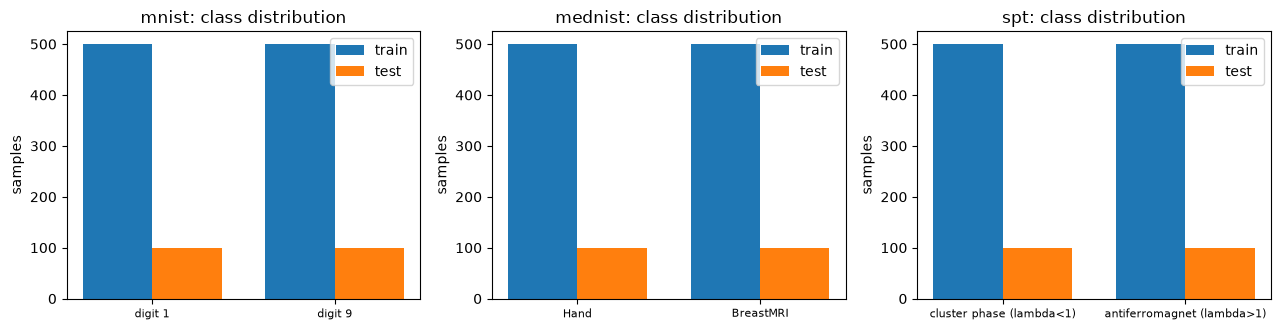

In [6]:
print("Input of every circuit: a real vector of 4096 amplitudes (= a 64 x 64 image, or a 12-qubit state), L2 norm 1.  Features = 4096 pixel / amplitude positions 'a_0 ... a_4095'.\n")
rows = []
for k, d in TASKS.items():
    for split in ("tr", "te"):
        y = d["y" + split].numpy()
        rows.append(dict(dataset=k, split={"tr": "train", "te": "test"}[split], shape=tuple(d["X" + split].shape),
                         class_0=CLASS_NAMES[k][0], n_0=int((y == 0).sum()), class_1=CLASS_NAMES[k][1], n_1=int((y == 1).sum())))
print(pd.DataFrame(rows).to_string(index=False))
print("\noriginal source labels -> task labels:  MNIST digit 1 -> 0, digit 9 -> 1 | MedNIST Hand -> 0, BreastMRI -> 1 | SPT lambda<1 (cluster) -> 0, lambda>1 (antiferromagnet) -> 1")
print("MNIST 1/9 pool (before sampling): train", {int(a): int(b) for a, b in zip(*np.unique(mn_ytr, return_counts=True))}, "test", {int(a): int(b) for a, b in zip(*np.unique(mn_yte, return_counts=True))},
      "| MedNIST pool: Hand", len(md_hand), "BreastMRI", len(md_breast), "| SPT grid:", len(spt_lam), "lambda values from", spt_lam.min(), "to", spt_lam.max())

fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, (k, d) in zip(axes, TASKS.items()):
    w = 0.38; xs = np.arange(2)
    ax.bar(xs - w / 2, torch.bincount(d["ytr"]).numpy(), w, label="train", color="tab:blue")
    ax.bar(xs + w / 2, torch.bincount(d["yte"]).numpy(), w, label="test", color="tab:orange")
    ax.set_xticks(xs); ax.set_xticklabels(CLASS_NAMES[k], fontsize=8); ax.set_title(f"{k}: class distribution"); ax.set_ylabel("samples"); ax.legend()
plt.tight_layout(); plt.show()

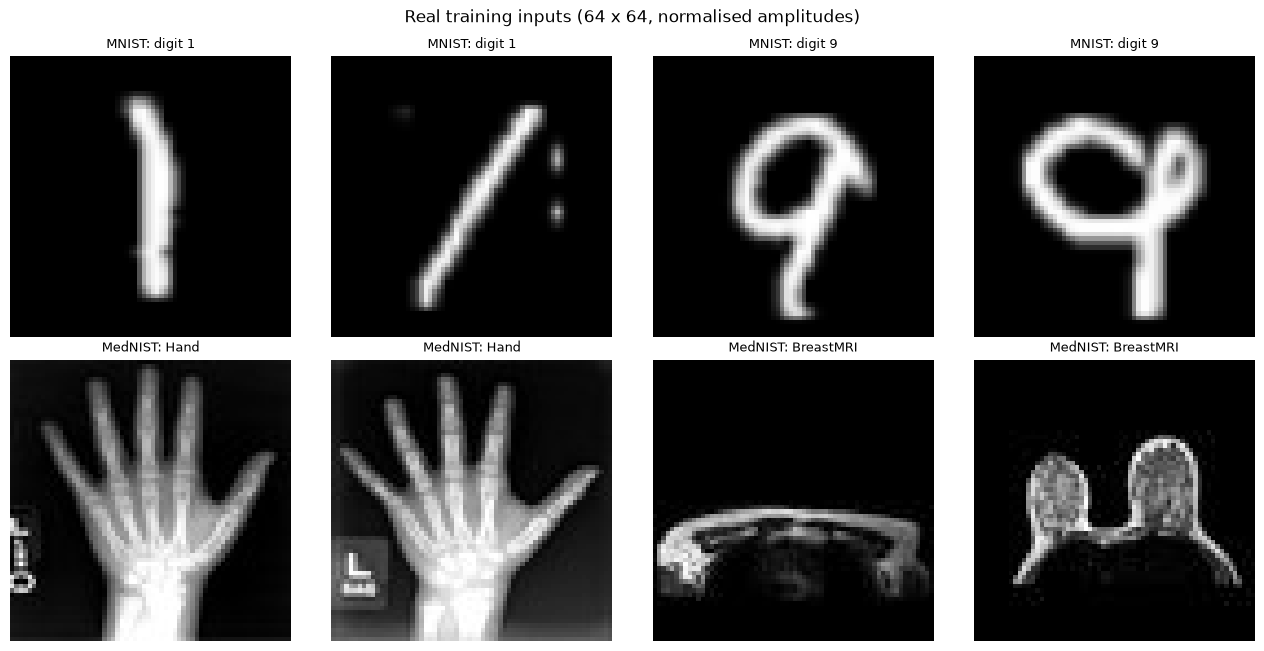

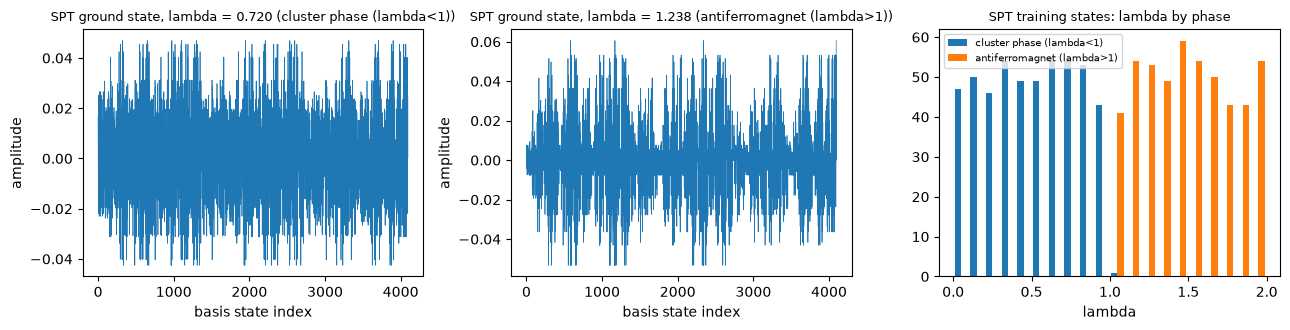

In [7]:
fig, axes = plt.subplots(2, 4, figsize=(13, 6.6))
for r, (k, title) in enumerate([("mnist", "MNIST"), ("mednist", "MedNIST")]):
    d = TASKS[k]
    for c in (0, 1):
        for j in range(2):
            i = int(np.where(d["ytr"].numpy() == c)[0][j])
            axes[r, 2 * c + j].imshow(d["Xtr"][i].reshape(64, 64), cmap="gray"); axes[r, 2 * c + j].axis("off")
            axes[r, 2 * c + j].set_title(f"{title}: {CLASS_NAMES[k][c]}", fontsize=9)
plt.suptitle("Real training inputs (64 x 64, normalised amplitudes)"); plt.tight_layout(); plt.show()

d = TASKS["spt"]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for c, ax in enumerate(axes[:2]):
    i = int(np.where(d["ytr"].numpy() == c)[0][0]); ax.plot(d["Xtr"][i].numpy(), lw=0.5)
    ax.set_title(f"SPT ground state, lambda = {d['lam_tr'][i]:.3f} ({CLASS_NAMES['spt'][c]})", fontsize=9); ax.set_xlabel("basis state index"); ax.set_ylabel("amplitude")
axes[2].hist([d["lam_tr"][d["ytr"].numpy() == c] for c in (0, 1)], bins=20, color=["tab:blue", "tab:orange"], label=CLASS_NAMES["spt"])
axes[2].set_xlabel("lambda"); axes[2].set_title("SPT training states: lambda by phase", fontsize=9); axes[2].legend(fontsize=7)
plt.tight_layout(); plt.show()

mnist explained variance of the two PCA components: [0.248 0.163]


mednist explained variance of the two PCA components: [0.275 0.099]


spt explained variance of the two PCA components: [0.905 0.093]


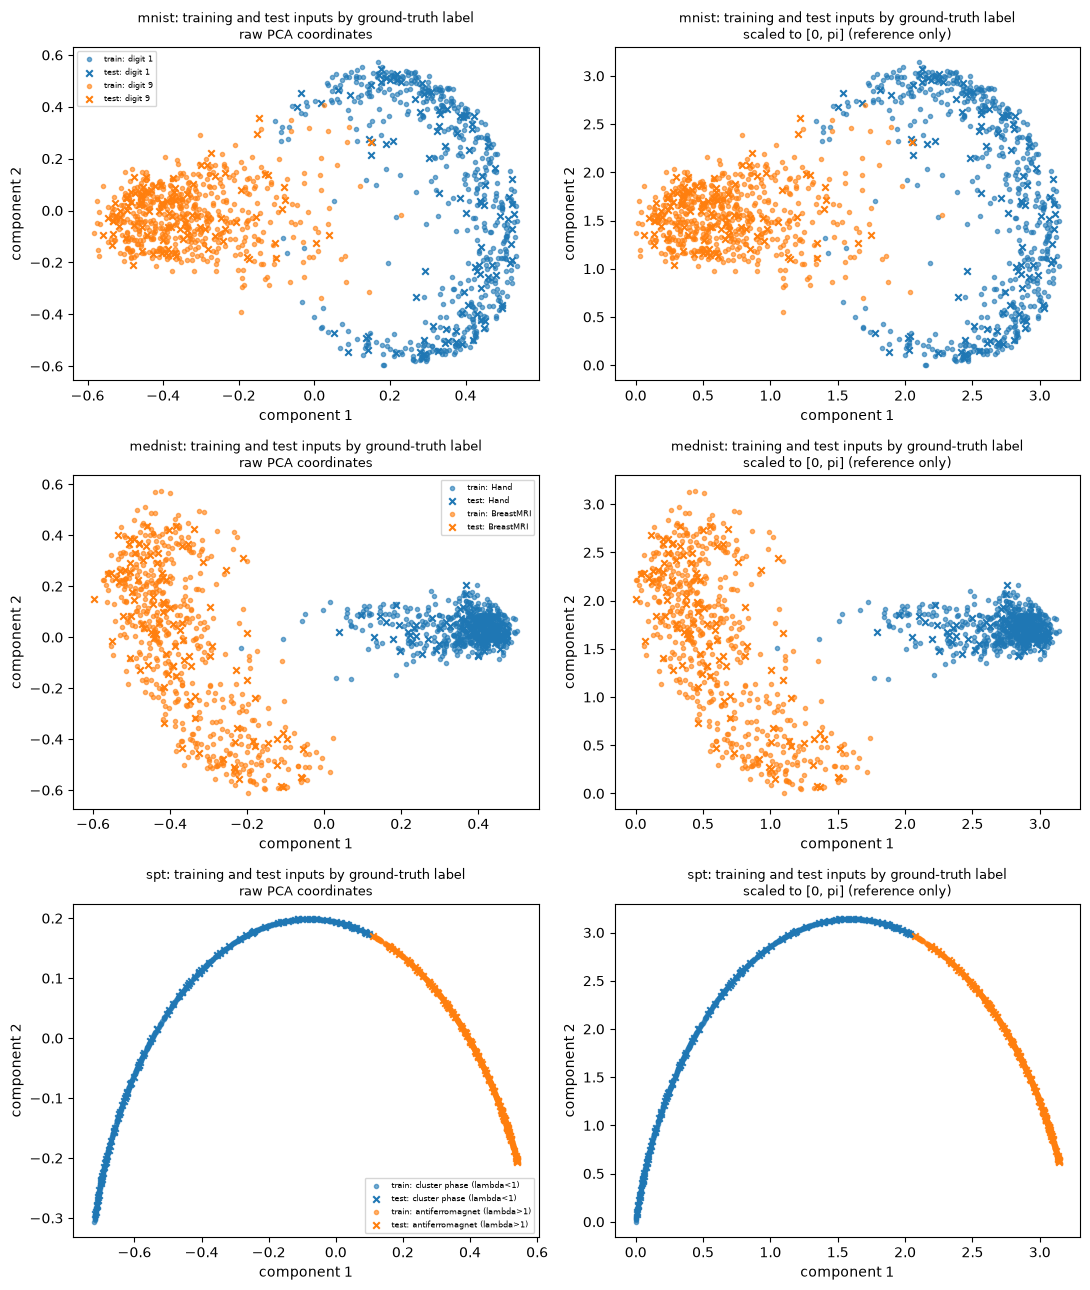

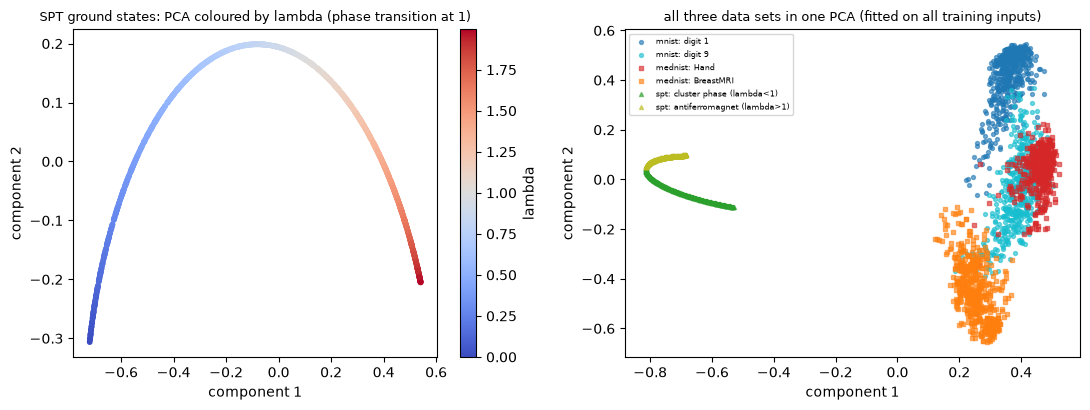

In [8]:
def pca_view(ax_raw, ax_ang, X, y, Xte, yte, names, title, colors=("tab:blue", "tab:orange")):
    """PCA fitted on the training split only; raw coordinates, then the same coordinates min-max scaled to [0, pi] (train-fitted, test clipped)."""
    pca = PCA(n_components=2, random_state=SEED).fit(X.numpy())
    Ztr, Zte = pca.transform(X.numpy()), pca.transform(Xte.numpy())
    sc = MinMaxScaler((0, np.pi)).fit(Ztr); Atr, Ate = sc.transform(Ztr), np.clip(sc.transform(Zte), 0, np.pi)
    for ax, (A, B), lab in ((ax_raw, (Ztr, Zte), "raw PCA coordinates"), (ax_ang, (Atr, Ate), "scaled to [0, pi] (reference only)")):
        for c in (0, 1):
            ax.scatter(A[y.numpy() == c, 0], A[y.numpy() == c, 1], s=9, alpha=0.6, color=colors[c], label=f"train: {names[c]}")
            ax.scatter(B[yte.numpy() == c, 0], B[yte.numpy() == c, 1], s=22, marker="x", color=colors[c], label=f"test: {names[c]}")
        ax.set_title(f"{title}\n{lab}", fontsize=9); ax.set_xlabel("component 1"); ax.set_ylabel("component 2")
    ax_raw.legend(fontsize=6)
    return pca.explained_variance_ratio_

fig, axes = plt.subplots(3, 2, figsize=(11, 13))
for r, k in enumerate(TASKS):
    d = TASKS[k]; ev = pca_view(axes[r, 0], axes[r, 1], d["Xtr"], d["ytr"], d["Xte"], d["yte"], CLASS_NAMES[k], f"{k}: training and test inputs by ground-truth label")
    print(k, "explained variance of the two PCA components:", np.round(ev, 3))
plt.tight_layout(); plt.show()

# SPT coloured by the continuous control parameter, and the two tasks together (heterogeneity)
d = TASKS["spt"]; pca = PCA(n_components=2, random_state=SEED).fit(d["Xtr"].numpy()); Z = pca.transform(d["Xtr"].numpy())
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
s = axes[0].scatter(Z[:, 0], Z[:, 1], c=d["lam_tr"], cmap="coolwarm", s=10); plt.colorbar(s, ax=axes[0], label="lambda"); axes[0].set_title("SPT ground states: PCA coloured by lambda (phase transition at 1)", fontsize=9)
axes[0].set_xlabel("component 1"); axes[0].set_ylabel("component 2")
allX = torch.cat([TASKS[k]["Xtr"] for k in TASKS]).numpy(); pj = PCA(n_components=2, random_state=SEED).fit(allX)
cols = {"mnist": ("tab:blue", "tab:cyan"), "mednist": ("tab:red", "tab:orange"), "spt": ("tab:green", "tab:olive")}
for k, mark in (("mnist", "o"), ("mednist", "s"), ("spt", "^")):
    Zk = pj.transform(TASKS[k]["Xtr"].numpy())
    for c in (0, 1): axes[1].scatter(Zk[TASKS[k]["ytr"].numpy() == c, 0], Zk[TASKS[k]["ytr"].numpy() == c, 1], s=8, marker=mark, color=cols[k][c], alpha=0.6, label=f"{k}: {CLASS_NAMES[k][c]}")
axes[1].set_title("all three data sets in one PCA (fitted on all training inputs)", fontsize=9); axes[1].legend(fontsize=6); axes[1].set_xlabel("component 1"); axes[1].set_ylabel("component 2")
plt.tight_layout(); plt.show()

## 2. An exact, differentiable simulator for the 12-qubit circuits

Training needs thousands of circuit evaluations and gradients with respect to the 720 parameters (and, for the attack, with respect to the 4096 input amplitudes). The paper used the Yao.jl simulator with automatic differentiation.
Here the same is done with a small **batched state-vector simulator in PyTorch**: a state is a complex vector of 4096 amplitudes per sample, the 12 single-qubit rotations of a layer are fused into three 16 x 16 blocks,
the CNOT ring is one fixed permutation of the 4096 basis states, and controlled rotations are diagonal phases (CRz) or masked rotations (CRx). Gradients come from PyTorch autograd. Qubit `q` is bit `q` of the basis-state index (qubit 1 of the paper = bit 0 = least significant),
which is the Yao convention, so the **last qubit (qubit 12) is the most significant bit of the pixel index** and is the one that is measured.
Because the simulator is hand-written, the circuit section below asserts that it gives the same output probabilities as the PennyLane circuits that are drawn there.

In [9]:
NQ, DIM = N_QUBITS, 2 ** N_QUBITS
CDT = torch.complex64
EYE2 = torch.eye(2, dtype=CDT)

def rx_mat(t):
    c = torch.cos(t / 2).to(CDT); s = torch.sin(t / 2).to(CDT)
    return torch.stack([torch.stack([c, -1j * s], -1), torch.stack([-1j * s, c], -1)], -2)
def rz_mat(t):
    e = torch.exp(-0.5j * t.to(CDT)); z = torch.zeros_like(e)
    return torch.stack([torch.stack([e, z], -1), torch.stack([z, e.conj()], -1)], -2)
def rot3(th):
    """Rx(th0) then Rz(th1) then Rx(th2) on one qubit as a single 2x2 matrix (applied in that time order)."""
    return rx_mat(th[..., 2]) @ rz_mat(th[..., 1]) @ rx_mat(th[..., 0])

def kron_chain(mats):
    K = mats[0]
    for M in mats[1:]:
        n = K.shape[-1]; P = K[..., :, None, :, None] * M[..., None, :, None, :]
        K = P.reshape(*P.shape[:-4], 2 * n, 2 * n)
    return K

def apply_layer(psi, Ul):
    """Ul: NQ matrices (...,2,2) or None (identity); one per qubit. The 12 gates are fused into three 16x16 blocks (qubits 0-3, 4-7, 8-11)."""
    B = psi.shape[0]
    G = [kron_chain([(Ul[q] if Ul[q] is not None else EYE2) for q in range(4 * g + 3, 4 * g - 1, -1)]) for g in range(3)]
    S = psi.reshape(B, 16, 16, 16)                          # [qubits 8-11, 4-7, 0-3]
    g0 = G[0].transpose(-1, -2); g0 = g0.unsqueeze(-3) if g0.dim() == 3 else g0
    S = torch.matmul(S, g0)
    g1 = G[1].unsqueeze(1) if G[1].dim() == 3 else G[1]
    S = torch.matmul(g1, S)
    return torch.matmul(G[2], S.reshape(B, 16, 256)).reshape(B, DIM)

IDX = torch.arange(DIM)
def bit(q): return (IDX >> q) & 1
def cnot_perm(pairs):
    """Basis-state permutation of a sequence of CNOT(control, target): new_state = state[:, perm]."""
    idx = IDX.clone()
    for c, t in pairs: idx = idx ^ (((idx >> c) & 1) << t)
    return torch.argsort(idx)

class _Perm(torch.autograd.Function):
    @staticmethod
    def forward(ctx, x, perm, inv):
        ctx.inv = inv; return x[:, perm]
    @staticmethod
    def backward(ctx, g): return g[:, ctx.inv], None, None
def permute_state(psi, perm): return _Perm.apply(psi, perm, torch.argsort(perm))

def apply_diag_crz(psi, th, pairs):
    """Product of controlled-Rz gates CRz(th_i) on (control, target) = pairs[i]; all are diagonal, so they commute and are applied as one phase."""
    M = torch.stack([((1 - 2 * bit(t)) * bit(c)).float() for c, t in pairs], 0)
    ph = th.reshape(-1, len(pairs)) @ M
    return psi * torch.exp(-0.5j * ph.to(CDT))
def apply_crx(psi, th, c, t):
    B = psi.shape[0]; U = rx_mat(th)
    if U.dim() == 2: U = U.expand(B, 2, 2)
    v = psi.reshape(B, 2 ** (NQ - 1 - t), 2, 2 ** t); a, b = v[:, :, 0, :], v[:, :, 1, :]
    e = lambda i, j: U[:, i, j].reshape(B, 1, 1)
    r = torch.stack([e(0, 0) * a + e(0, 1) * b, e(1, 0) * a + e(1, 1) * b], 2).reshape(B, DIM)
    return torch.where(bit(c).bool()[None, :], r, psi)

PERM_RING = cnot_perm([(i, (i + 1) % NQ) for i in range(NQ)])

class FCCircuit:
    """Fully connected classifier: `depth` x [Rx-Rz-Rx on every qubit, ring of CNOTs]; 3 * 12 * depth parameters."""
    name = "FC"
    def __init__(s, depth=DEPTH): s.depth = depth; s.nparams = depth * NQ * 3
    def evolve(s, psi, th):
        th = th.reshape(*th.shape[:-1], s.depth, NQ, 3)
        for d in range(s.depth):
            U = rot3(th[..., d, :, :])
            psi = apply_layer(psi, [U[..., q, :, :] for q in range(NQ)])
            psi = permute_state(psi, PERM_RING)
        return psi

class QCNNCircuit:
    """QCNN (CHOICE of gate list; the paper only shows a figure): 2 x [conv, pool] (12 -> 6 -> 3 active qubits), then `fc_depth` fully connected layers on the 3 remaining qubits."""
    name = "QCNN"
    def __init__(s, fc_depth=DEPTH): s.fc_depth = fc_depth; s.nparams = 4 * 12 + 2 * 6 + 4 * 6 + 2 * 3 + fc_depth * 9
    def evolve(s, psi, th):
        o = 0; lead = th.shape[:-1]
        def take(n):
            nonlocal o
            r = th[..., o:o + n]; o += n; return r
        act = list(range(NQ))
        for _ in range(2):
            m = len(act)
            R = rot3(take(3 * m).reshape(*lead, m, 3)); Ul = [None] * NQ
            for i, q in enumerate(act): Ul[q] = R[..., i, :, :]
            psi = apply_layer(psi, Ul)                                                         # convolution: single-qubit rotations ...
            psi = apply_diag_crz(psi, take(m), [(act[i], act[(i + 1) % m]) for i in range(m)])  # ... and trainable CRz between neighbours (ring)
            pp = take(m); pairs = [(act[2 * i], act[2 * i + 1]) for i in range(m // 2)]
            psi = apply_diag_crz(psi, pp[..., 0::2], pairs)                                    # pooling: CRz, CRx from the even to the odd qubit of each pair
            for i, (c, t) in enumerate(pairs): psi = apply_crx(psi, pp[..., 2 * i + 1], c, t)
            act = act[1::2]                                                                    # the even qubits are never touched again
        perm = cnot_perm([(act[i], act[(i + 1) % 3]) for i in range(3)])
        F = rot3(take(s.fc_depth * 9).reshape(*lead, s.fc_depth, 3, 3))
        for d in range(s.fc_depth):
            Ul = [None] * NQ
            for i, q in enumerate(act): Ul[q] = F[..., d, i, :, :]
            psi = permute_state(apply_layer(psi, Ul), perm)
        assert o == s.nparams
        return psi

def forward(model, x, th):
    """Class probabilities (N, 2) from the measurement of the last qubit. x: real (N, 4096), normalised here (so gradients w.r.t. x are well defined). th: (P,) or one parameter set per sample (N, P)."""
    x = x / x.norm(dim=1, keepdim=True)
    psi = model.evolve(x.to(CDT), th)
    q1 = (psi[:, DIM // 2:].abs() ** 2).sum(1)                   # P(qubit 12 = 1)
    return torch.stack([1 - q1, q1], 1)
def ce(p, y): return -torch.log(p.gather(1, y[:, None]).squeeze(1).clamp_min(1e-12))

ARCH = {"FC": FCCircuit(), "QCNN": QCNNCircuit()}
print({k: v.nparams for k, v in ARCH.items()}, "trainable parameters")

{'FC': 720, 'QCNN': 270} trainable parameters


In [10]:
# Sanity checks of the simulator: (1) autograd input-gradient against central finite differences, (2) per-sample parameter copies against a loop.
g = torch.Generator().manual_seed(0)
for name, M in ARCH.items():
    th = torch.randn(M.nparams, generator=g); x = TASKS["mnist"]["Xte"][:2].clone(); y = TASKS["mnist"]["yte"][:2]
    x.requires_grad_(True); (gx,) = torch.autograd.grad(ce(forward(M, x, th), y).sum(), x)
    idx = [int(i) for i in torch.argsort(-gx[0].abs())[:3]]; errs = []
    for i in idx:
        e = torch.zeros(DIM); e[i] = 1e-2
        f = lambda xx: float(ce(forward(M, xx[None], th), y[:1]).sum())
        fd = (f(x[0].detach() + e) - f(x[0].detach() - e)) / 2e-2; errs.append(abs(fd - float(gx[0, i])) / (abs(fd) + 1e-6))
    thb = th.repeat(2, 1).requires_grad_(); (gb,) = torch.autograd.grad(ce(forward(M, x.detach(), thb), y).sum(), thb)
    th1 = th.clone().requires_grad_(); (g1,) = torch.autograd.grad(ce(forward(M, x.detach()[:1], th1), y[:1]).sum(), th1)
    print(f"{name}: relative error of d loss / d amplitude vs finite differences {max(errs):.2e} | per-sample parameter gradient vs loop {float((gb[0]-g1).abs().max()):.2e}")
    assert max(errs) < 5e-2 and float((gb[0] - g1).abs().max()) < 1e-4

FC: relative error of d loss / d amplitude vs finite differences 1.83e-04 | per-sample parameter gradient vs loop 1.79e-07


QCNN: relative error of d loss / d amplitude vs finite differences 6.52e-05 | per-sample parameter gradient vs loop 1.19e-07


## Quantum Circuit Architecture

The two circuits that are trained and attacked are built here **a second time in PennyLane** (`qml.StatePrep` amplitude encoding, `qml.RX`, `qml.RZ`, `qml.CNOT`, `qml.CRZ`, `qml.CRX`, measurement of the last qubit with `qml.probs`) with the same gate order, and
the PyTorch simulator is asserted to give the same class probabilities on real MNIST test inputs and random parameters (maximum absolute difference below `1e-5`; the same assertion is repeated for the trained parameters after training).
PennyLane wire `w` is paper qubit `w + 1`; its state-vector index is big-endian, so the amplitudes are bit-reversed before `StatePrep` to match the simulator's little-endian pixel order.
The drawings are of the PennyLane circuits (`qml.draw_mpl`) with real input data and parameter values.

**Assumptions where the paper omits circuit details** (see also the table at the top): the CNOT ring order, the QCNN gate list and the pooling (which qubit is kept), the input encoding order (bit-reversal convention), and Rx-Rz-Rx rather than Rz-Rx-Rz in the parameterised layers.

In [11]:
BITREV = np.array([int(format(i, "012b")[::-1], 2) for i in range(DIM)])

def make_pl_circuit(kind, depth=DEPTH):
    dev = qml.device("default.qubit", wires=NQ)
    @qml.qnode(dev, interface="numpy")
    def circ(x, th):
        qml.StatePrep(x[BITREV], wires=range(NQ), normalize=True)            # amplitude encoding of the 64 x 64 input
        if kind == "FC":
            t = th.reshape(depth, NQ, 3)
            for d in range(depth):
                for q in range(NQ):
                    qml.RX(t[d, q, 0], wires=q); qml.RZ(t[d, q, 1], wires=q); qml.RX(t[d, q, 2], wires=q)      # parameterised layer
                for q in range(NQ): qml.CNOT(wires=[q, (q + 1) % NQ])                                          # entangling layer (ring)
        else:
            o = 0; act = list(range(NQ))
            for _ in range(2):
                m = len(act); R = th[o:o + 3 * m].reshape(m, 3); o += 3 * m
                for i, q in enumerate(act):
                    qml.RX(R[i, 0], wires=q); qml.RZ(R[i, 1], wires=q); qml.RX(R[i, 2], wires=q)               # convolution
                cr = th[o:o + m]; o += m
                for i in range(m): qml.CRZ(cr[i], wires=[act[i], act[(i + 1) % m]])
                pp = th[o:o + m]; o += m
                for i in range(m // 2):                                                                          # pooling
                    qml.CRZ(pp[2 * i], wires=[act[2 * i], act[2 * i + 1]]); qml.CRX(pp[2 * i + 1], wires=[act[2 * i], act[2 * i + 1]])
                act = act[1::2]
            F = th[o:o + depth * 9].reshape(depth, 3, 3)
            for d in range(depth):
                for i, q in enumerate(act):
                    qml.RX(F[d, i, 0], wires=q); qml.RZ(F[d, i, 1], wires=q); qml.RX(F[d, i, 2], wires=q)
                for i in range(3): qml.CNOT(wires=[act[i], act[(i + 1) % 3]])
        return qml.probs(wires=NQ - 1)                                           # measurement of the last qubit (qubit 12)
    return circ

def assert_simulator_equals_pennylane(name, th, X, tol=1e-5):
    circ = make_pl_circuit(name)
    ref = np.stack([circ(X[i].numpy().astype(np.float64), th.numpy().astype(np.float64)) for i in range(len(X))])
    with torch.no_grad(): mine = forward(ARCH[name], X, th).numpy()
    err = np.abs(ref - mine).max(); assert err < tol, (name, err)
    return err

g = torch.Generator().manual_seed(1); X3 = TASKS["mnist"]["Xte"][:3]
for name in ARCH:
    th = (torch.rand(ARCH[name].nparams, generator=g) * 2 - 1) * math.pi
    print(f"{name}: PyTorch simulator vs PennyLane on 3 real MNIST test inputs, max |difference of class probabilities| = {assert_simulator_equals_pennylane(name, th, X3):.2e}  (assertion passed)")

FC: PyTorch simulator vs PennyLane on 3 real MNIST test inputs, max |difference of class probabilities| = 3.86e-07  (assertion passed)


QCNN: PyTorch simulator vs PennyLane on 3 real MNIST test inputs, max |difference of class probabilities| = 1.08e-07  (assertion passed)


In [12]:
x0 = TASKS["mnist"]["Xte"][0].numpy().astype(np.float64); rng_c = np.random.default_rng(0)
def circuit_report(name, th, label):
    circ = make_pl_circuit(name); specs = qml.specs(circ)(x0, th)
    res = specs.resources
    print(f"{label}: qubits = {specs.num_device_wires}, depth = {res.depth}, gates = {res.num_gates}, trainable parameters = {len(th)}, gate counts = {dict(res.gate_types)}")
    return circ

th_fc = rng_c.uniform(-np.pi, np.pi, ARCH["FC"].nparams); th_q = rng_c.uniform(-np.pi, np.pi, ARCH["QCNN"].nparams)
circuit_report("FC", th_fc, "Fully connected (depth 20, executed in E1 and E3)")
circuit_report("QCNN", th_q, "QCNN (executed in E2)")
print("depth counts the StatePrep amplitude-encoding box as one layer.")

Fully connected (depth 20, executed in E1 and E3): qubits = 12, depth = 301, gates = 961, trainable parameters = 720, gate counts = {'StatePrep': 1, 'RX': 480, 'RZ': 240, 'CNOT': 240}
QCNN (executed in E2): qubits = 12, depth = 149, gates = 331, trainable parameters = 270, gate counts = {'StatePrep': 1, 'RX': 156, 'RZ': 78, 'CRZ': 27, 'CRX': 9, 'CNOT': 60}
depth counts the StatePrep amplitude-encoding box as one layer.


### Fully connected circuit: one depth (parameterised layer + CNOT ring), then the complete depth-20 circuit

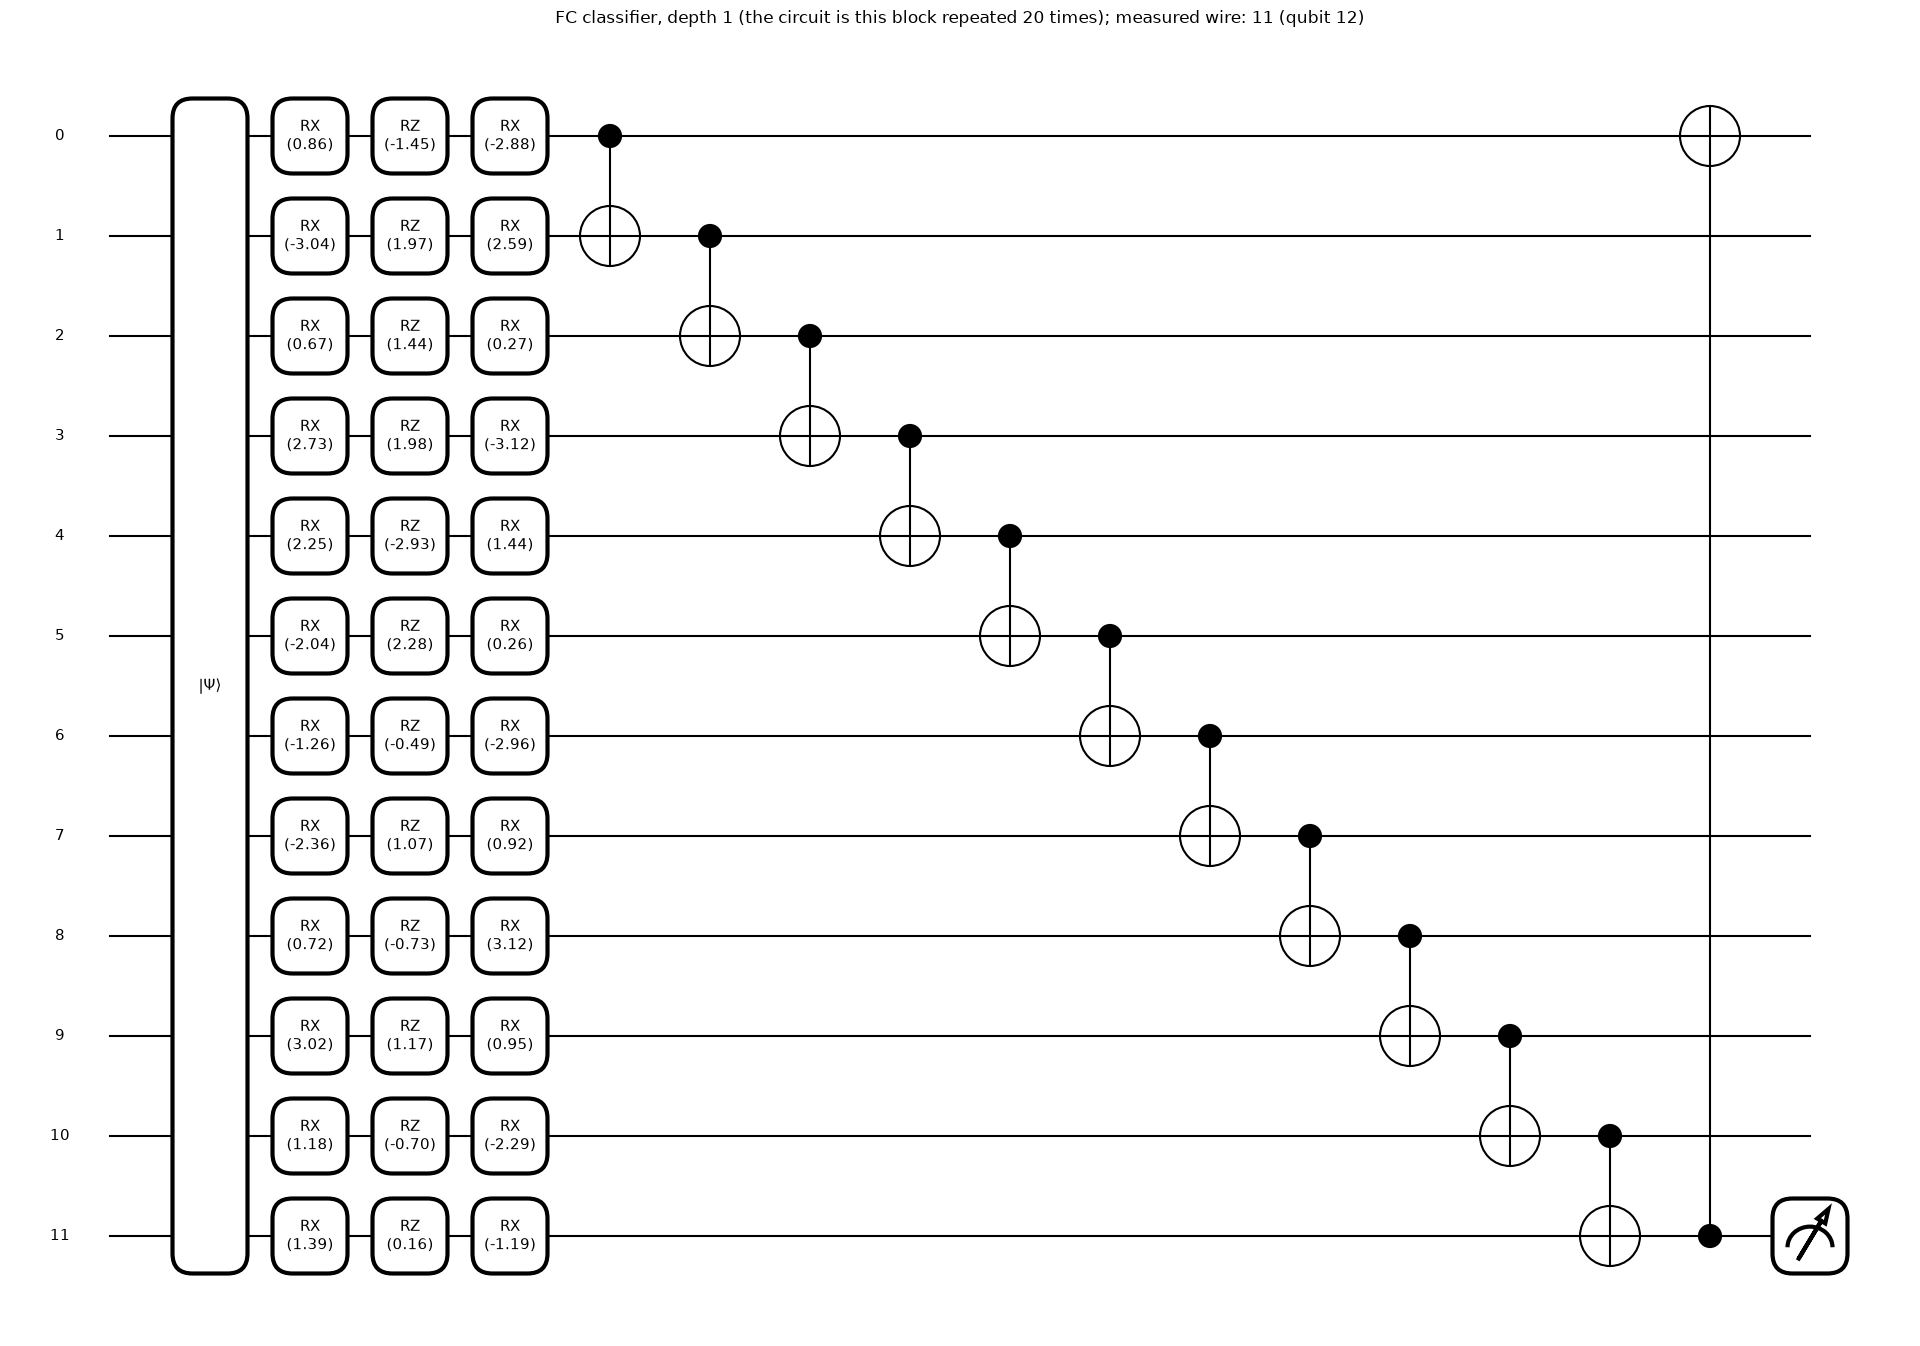

In [13]:
one = make_pl_circuit("FC", depth=1)
fig, ax = qml.draw_mpl(one, decimals=2, fontsize=11)(x0, th_fc[:NQ * 3]); fig.suptitle("FC classifier, depth 1 (the circuit is this block repeated 20 times); measured wire: 11 (qubit 12)", y=1.02); plt.show()

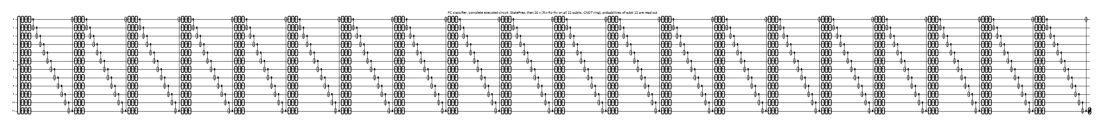

In [14]:
full = make_pl_circuit("FC", depth=DEPTH)
fig, ax = qml.draw_mpl(full, decimals=None, fontsize=7)(x0, th_fc)
fig.set_size_inches(60, 6); fig.suptitle("FC classifier, complete executed circuit: StatePrep, then 20 x [Rx-Rz-Rx on all 12 qubits, CNOT ring]; probabilities of qubit 12 are read out", y=1.0)
buf = io.BytesIO(); fig.savefig(buf, format="png", dpi=40, bbox_inches="tight"); plt.close(fig); buf.seek(0)
plt.figure(figsize=(14, 3.2)); plt.imshow(plt.imread(buf)); plt.axis("off"); plt.show()

### QCNN circuit: convolution, pooling, convolution, pooling, then 20 fully connected layers on three qubits

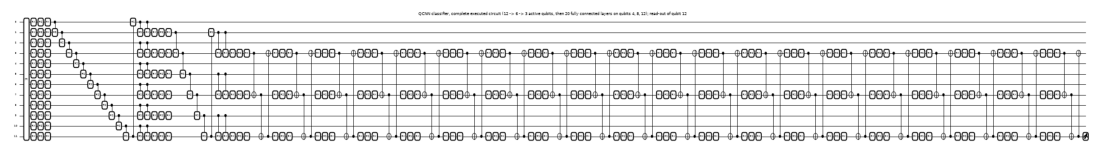

In [15]:
fig, ax = qml.draw_mpl(make_pl_circuit("QCNN"), decimals=None, fontsize=7)(x0, th_q)
fig.set_size_inches(48, 6); fig.suptitle("QCNN classifier, complete executed circuit (12 -> 6 -> 3 active qubits, then 20 fully connected layers on qubits 4, 8, 12); read-out of qubit 12", y=1.0)
buf = io.BytesIO(); fig.savefig(buf, format="png", dpi=40, bbox_inches="tight"); plt.close(fig); buf.seek(0)
plt.figure(figsize=(14, 3.6)); plt.imshow(plt.imread(buf)); plt.axis("off"); plt.show()

## 3. Quantum continual learning with elastic weight consolidation (paper Sec. II.C and III.A)

**Task A** (MNIST 1 vs 9) is learned first: Adam, cross-entropy of the two measurement probabilities, class = larger probability (threshold 0.5).
**Fisher information.** The diagonal of the empirical Fisher matrix on the task-A training samples, `F_i = mean_x (d log p(y|x) / d theta_i)^2`, is computed with one parameter copy per sample, so a single backward pass gives all per-sample gradients.
**Task B** starts from the task-A parameters and minimises `L_B(theta) + (lambda/2) * sum_i F_i (theta_i - theta_A,i)^2` (paper Eq. 8; its gradient is the "EWCpunish" term of Eq. 9). The curves recorded after every epoch are the test accuracy and loss of **both** tasks, so forgetting would be visible.
The parameters of the fully connected circuit after task A are shared by experiments E1 and E3 (the paper's first training stage is the same for both); the QCNN has its own task-A stage.

In [16]:
INIT_STD = 0.1           # CHOICE: initial angles ~ Normal(0, 0.1^2). Chosen in a development pilot (300 Adam steps, lr 0.005, batch 100, 1000 MNIST 1/9 training images, 200 validation images cut from the MNIST
                         # training set, the test set was not used): uniform[0, 2pi), N(0, 0.1^2) and N(0, 1) all reached 99.5 % validation accuracy; validation loss 0.479, 0.370 and 0.484 respectively.

def init_params(model, seed):
    g = torch.Generator().manual_seed(seed)
    return torch.randn(model.nparams, generator=g) * INIT_STD

@torch.no_grad()
def predict_p(fn, X, bs=200):
    return torch.cat([fn(X[i:i + bs]) for i in range(0, len(X), bs)])

def acc_loss(fn, X, y):
    p = predict_p(fn, X); return float((p.argmax(1) == y).float().mean() * 100), float(ce(p, y).mean())

def train_task(model, X, y, th0, epochs, lr, batch, seed, evalsets, fisher=None, th_ref=None, lam=0.0, tag=""):
    """Adam on the cross-entropy (+ EWC penalty). After every epoch the test accuracy / loss of the sets in `evalsets` is recorded (for the training-curve figures only; nothing is selected on them)."""
    th = th0.clone().requires_grad_(True); opt = torch.optim.Adam([th], lr=lr)
    gen = torch.Generator().manual_seed(seed); N = len(X); hist = []; t0 = time.time()
    for ep in range(epochs):
        perm = torch.randperm(N, generator=gen)
        for i in range(0, N, batch):
            idx = perm[i:i + batch]; loss = ce(forward(model, X[idx], th), y[idx]).mean()
            if fisher is not None: loss = loss + 0.5 * lam * (fisher * (th - th_ref) ** 2).sum()
            opt.zero_grad(); loss.backward(); opt.step()
        row = {"epoch": ep + 1, "batch_loss": float(loss)}
        for nm, (Xe, ye) in evalsets.items():
            a, l = acc_loss(lambda x: forward(model, x, th.detach()), Xe, ye); row[f"acc_{nm}"] = a; row[f"loss_{nm}"] = l
        hist.append(row)
        print(f"  {tag} epoch {ep+1:2d}/{epochs} | " + " | ".join(f"{k} {v:.3f}" for k, v in row.items() if k != "epoch") + f" | {time.time()-t0:.0f} s", flush=True)
    return th.detach(), pd.DataFrame(hist)

def fisher_diag(model, X, y, th, chunk=100):
    """Diagonal empirical Fisher information: mean over samples of (grad of log p(y|x))^2, one parameter copy per sample."""
    F = torch.zeros_like(th)
    for i in range(0, len(X), chunk):
        xb, yb = X[i:i + chunk], y[i:i + chunk]
        thb = th.detach().repeat(len(xb), 1).requires_grad_(True)
        (g,) = torch.autograd.grad((-ce(forward(model, xb, thb), yb)).sum(), thb)
        F += (g ** 2).sum(0)
    return F / len(X)

In [17]:
STORE = {}          # (experiment, seed) -> trained parameters, histories
TRAIN_TIME = {}
t_all = time.time()
for seed in RUN_SEEDS:
    for arch in ("FC", "QCNN"):
        model = ARCH[arch]; A = TASKS["mnist"]; ea, eb = EPOCHS[arch]
        t0 = time.time(); print(f"[seed {seed}] {arch}: task A (MNIST 1 vs 9), {ea} epochs, {model.nparams} parameters")
        thA, histA = train_task(model, A["Xtr"], A["ytr"], init_params(model, seed), ea, LR, BATCH, seed, {"A": (A["Xte"], A["yte"])}, tag=f"{arch}/A")
        F = fisher_diag(model, A["Xtr"], A["ytr"], thA)
        print(f"  Fisher diagonal: mean {float(F.mean()):.3e}, max {float(F.max()):.3e}  ({time.time()-t0:.0f} s so far)")
        for exp, cfg in EXPERIMENTS.items():
            if cfg["arch"] != arch: continue
            B = TASKS[cfg["task_b"]]
            print(f"[seed {seed}] {exp}: task B ({cfg['task_b']}), {eb} epochs, EWC lambda = {cfg['lam_ewc']}")
            thAB, histB = train_task(model, B["Xtr"], B["ytr"], thA, eb, LR, BATCH, seed, {"A": (A["Xte"], A["yte"]), "B": (B["Xte"], B["yte"])},
                                     fisher=F, th_ref=thA, lam=cfg["lam_ewc"], tag=f"{exp}/B")
            accA0, _ = acc_loss(lambda x: forward(model, x, thA), A["Xte"], A["yte"])
            STORE[(exp, seed)] = dict(thA=thA, thAB=thAB, histA=histA, histB=histB, fisher=F, accA_alone=accA0)
        TRAIN_TIME[(arch, seed)] = time.time() - t0
print(f"training finished in {(time.time()-t_all)/60:.1f} min")
for (exp, seed), st in STORE.items():
    h = st["histB"].iloc[-1]
    print(f"{exp} seed {seed}: task A alone {st['accA_alone']:.1f} % | merged: task A {h['acc_A']:.1f} %, task B {h['acc_B']:.1f} %, average {(h['acc_A']+h['acc_B'])/2:.1f} %")

[seed 42] FC: task A (MNIST 1 vs 9), 30 epochs, 720 parameters


  FC/A epoch  1/30 | batch_loss 0.655 | acc_A 94.500 | loss_A 0.645 | 63 s


  FC/A epoch  2/30 | batch_loss 0.612 | acc_A 98.500 | loss_A 0.604 | 127 s


  FC/A epoch  3/30 | batch_loss 0.590 | acc_A 99.500 | loss_A 0.573 | 192 s


  FC/A epoch  4/30 | batch_loss 0.555 | acc_A 99.500 | loss_A 0.551 | 261 s


...

  E2/B epoch  7/10 | batch_loss 0.688 | acc_A 98.000 | loss_A 0.362 | acc_B 65.000 | loss_B 0.646 | 360 s


  E2/B epoch  8/10 | batch_loss 0.674 | acc_A 98.000 | loss_A 0.363 | acc_B 65.500 | loss_B 0.644 | 416 s


  E2/B epoch  9/10 | batch_loss 0.673 | acc_A 97.500 | loss_A 0.369 | acc_B 70.500 | loss_B 0.635 | 455 s


  E2/B epoch 10/10 | batch_loss 0.676 | acc_A 97.500 | loss_A 0.371 | acc_B 70.500 | loss_B 0.633 | 497 s


training finished in 108.2 min
E1 seed 42: task A alone 99.0 % | merged: task A 80.5 %, task B 100.0 %, average 90.2 %
E3 seed 42: task A alone 99.0 % | merged: task A 96.5 %, task B 93.5 %, average 95.0 %
E2 seed 42: task A alone 98.5 % | merged: task A 97.5 %, task B 70.5 %, average 84.0 %


In [18]:
# The trained parameters go through the same equivalence assertion as the random ones above.
for (exp, seed), st in STORE.items():
    cfg = EXPERIMENTS[exp]; Xs = torch.cat([TASKS["mnist"]["Xte"][:2], TASKS[cfg["task_b"]]["Xte"][:2]])
    print(f"{exp}: trained parameters, PyTorch simulator vs PennyLane on 4 real test inputs: max |dp| = {assert_simulator_equals_pennylane(cfg['arch'], st['thAB'], Xs):.2e} (assertion passed)")

E1: trained parameters, PyTorch simulator vs PennyLane on 4 real test inputs: max |dp| = 1.48e-06 (assertion passed)


E3: trained parameters, PyTorch simulator vs PennyLane on 4 real test inputs: max |dp| = 3.59e-07 (assertion passed)


E2: trained parameters, PyTorch simulator vs PennyLane on 4 real test inputs: max |dp| = 3.35e-07 (assertion passed)


### Re-drawing the training curves (paper Fig. 1, 4 and 6)

Left: task-A training (test accuracy and loss on MNIST). Right: EWC training on task B: test accuracy on both tasks and the loss on both tasks per epoch. The task-A curve in the right panel shows how much of task A is kept.

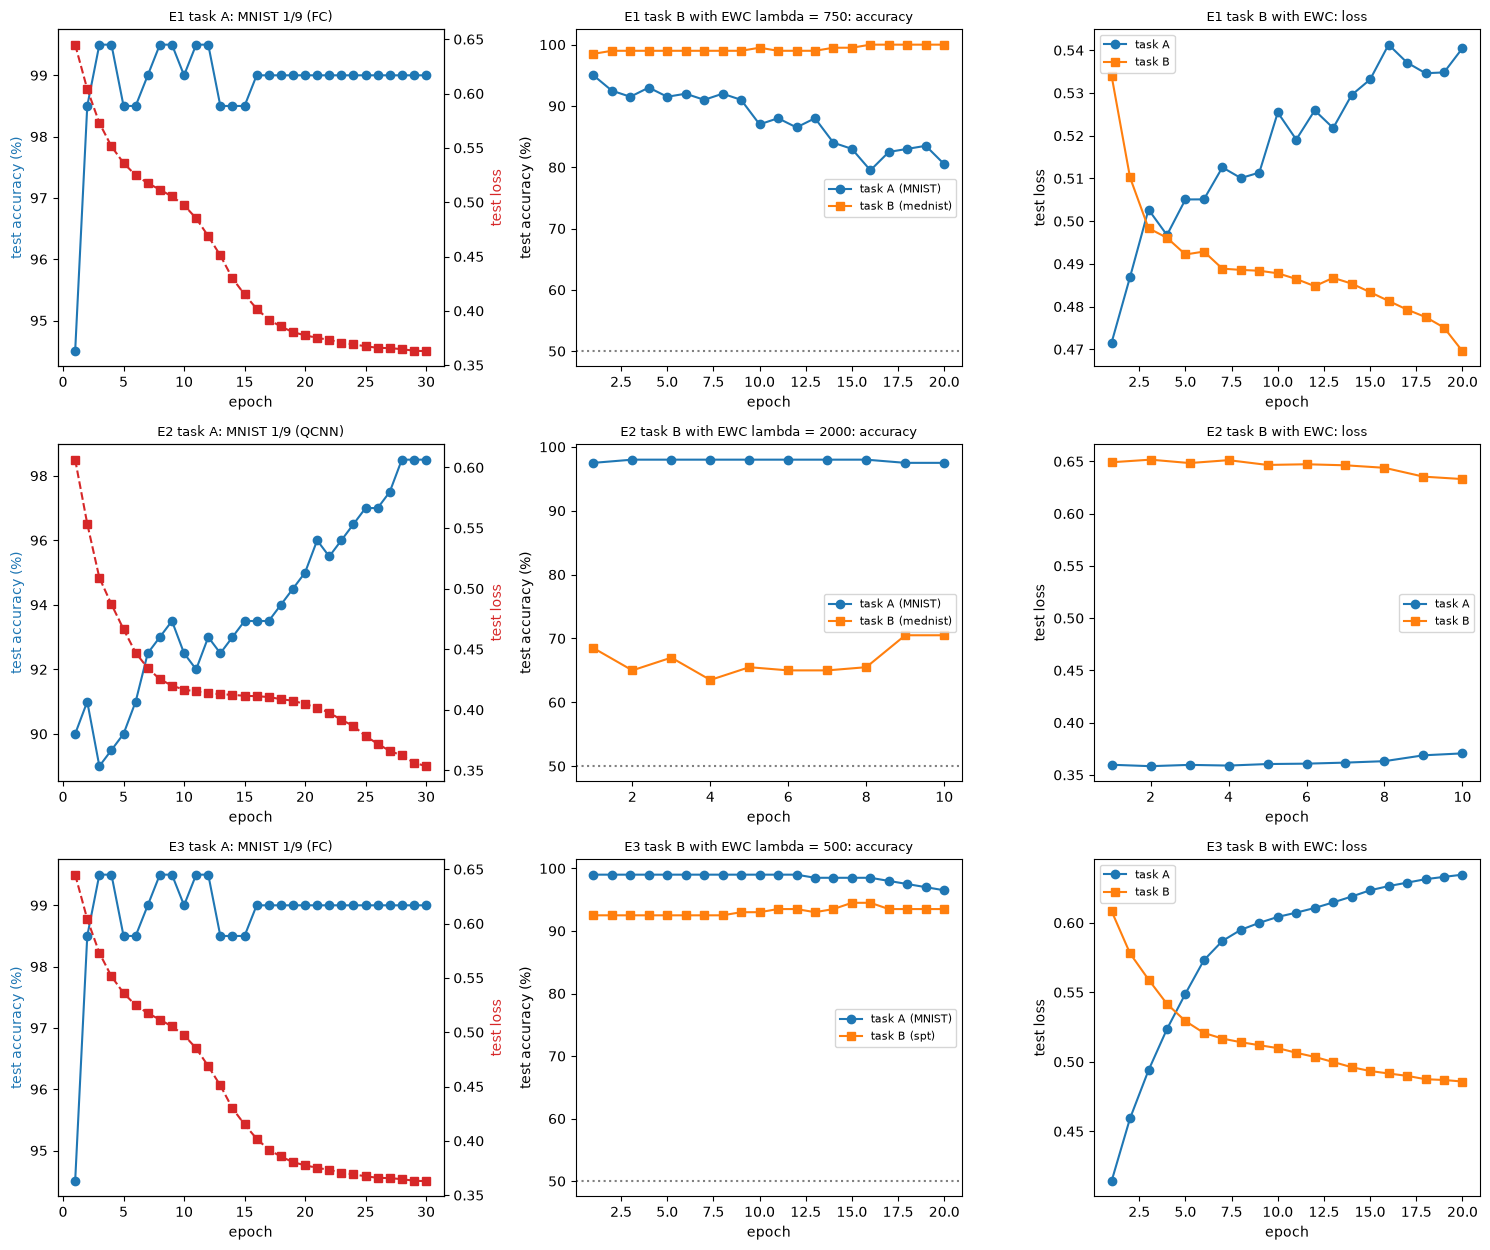

In [19]:
seed0 = RUN_SEEDS[0]
fig, axes = plt.subplots(len(EXPERIMENTS), 3, figsize=(15, 4.2 * len(EXPERIMENTS)))
for r, (exp, cfg) in enumerate(EXPERIMENTS.items()):
    st = STORE[(exp, seed0)]; hA, hB = st["histA"], st["histB"]
    ax = axes[r, 0]; ax.plot(hA.epoch, hA.acc_A, "o-", color="tab:blue"); ax.set_ylabel("test accuracy (%)", color="tab:blue"); ax.set_xlabel("epoch"); ax.set_title(f"{exp} task A: MNIST 1/9 ({cfg['arch']})", fontsize=9)
    ax2 = ax.twinx(); ax2.plot(hA.epoch, hA.loss_A, "s--", color="tab:red"); ax2.set_ylabel("test loss", color="tab:red")
    ax = axes[r, 1]; ax.plot(hB.epoch, hB.acc_A, "o-", label="task A (MNIST)"); ax.plot(hB.epoch, hB.acc_B, "s-", label=f"task B ({cfg['task_b']})")
    ax.axhline(50, color="gray", ls=":"); ax.set_xlabel("epoch"); ax.set_ylabel("test accuracy (%)"); ax.set_title(f"{exp} task B with EWC lambda = {cfg['lam_ewc']}: accuracy", fontsize=9); ax.legend(fontsize=8)
    ax = axes[r, 2]; ax.plot(hB.epoch, hB.loss_A, "o-", label="task A"); ax.plot(hB.epoch, hB.loss_B, "s-", label="task B"); ax.set_xlabel("epoch"); ax.set_ylabel("test loss"); ax.set_title(f"{exp} task B with EWC: loss", fontsize=9); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 4. Classical baseline on the same inputs

The paper has no classical comparison. To judge whether the vulnerability is specific to the quantum circuit, a small classical network (MLP 4096-64-2, ReLU) is trained on **exactly the same normalised 4096-vectors** of both tasks (jointly, class labels 0/1 for each task, Adam lr 0.001, batch 100),
and an SVC (RBF) and a random forest are fitted on the same data. They are attacked later with the same procedure.

In [20]:
class MLP(nn.Module):
    def __init__(s): super().__init__(); s.net = nn.Sequential(nn.Linear(DIM, 64), nn.ReLU(), nn.Linear(64, 2))
    def forward(s, x): return Fn.softmax(s.net(x / x.norm(dim=1, keepdim=True) * math.sqrt(DIM)), dim=1)   # CHOICE: inputs rescaled to unit RMS per entry so that Adam lr 0.001 trains quickly

def train_mlp(Xtr, ytr, seed, epochs=MLP_EPOCHS):
    torch.manual_seed(seed); net = MLP(); opt = torch.optim.Adam(net.parameters(), lr=1e-3); gen = torch.Generator().manual_seed(seed)
    for ep in range(epochs):
        perm = torch.randperm(len(Xtr), generator=gen)
        for i in range(0, len(Xtr), 100):
            idx = perm[i:i + 100]; loss = ce(net(Xtr[idx]), ytr[idx]).mean(); opt.zero_grad(); loss.backward(); opt.step()
    return net.eval()

BASE = {}
for (exp, seed) in STORE:
    cfg = EXPERIMENTS[exp]; A, B = TASKS["mnist"], TASKS[cfg["task_b"]]
    Xtr, ytr = torch.cat([A["Xtr"], B["Xtr"]]), torch.cat([A["ytr"], B["ytr"]])
    net = train_mlp(Xtr, ytr, seed)
    rf = RandomForestClassifier(n_estimators=200, random_state=seed, n_jobs=1).fit(Xtr.numpy(), ytr.numpy())
    svc = SVC(kernel="rbf", C=10.0, gamma="scale", random_state=seed).fit(Xtr.numpy(), ytr.numpy())
    BASE[(exp, seed)] = dict(mlp=net, rf=rf, svc=svc)
    accs = {nm: [acc_loss(lambda x: net(x), T["Xte"], T["yte"])[0] if nm == "MLP" else float((m.predict(T["Xte"].numpy()) == T["yte"].numpy()).mean() * 100)
                 for T in (A, B)] for nm, m in (("MLP", net), ("RandomForest", rf), ("SVC(rbf)", svc))}
    print(f"{exp} seed {seed} classical baselines, clean test accuracy (task A %, task B %):", {k: tuple(round(a, 1) for a in v) for k, v in accs.items()})

E1 seed 42 classical baselines, clean test accuracy (task A %, task B %): {'MLP': (99.5, 99.0), 'RandomForest': (99.5, 99.5), 'SVC(rbf)': (99.5, 100.0)}


E3 seed 42 classical baselines, clean test accuracy (task A %, task B %): {'MLP': (99.5, 99.5), 'RandomForest': (99.0, 100.0), 'SVC(rbf)': (99.5, 100.0)}


E2 seed 42 classical baselines, clean test accuracy (task A %, task B %): {'MLP': (99.5, 99.0), 'RandomForest': (99.5, 99.5), 'SVC(rbf)': (99.5, 100.0)}


## 5. The universal perturbation: quantum basic iterative method (paper Algorithm 1)

The 400 test samples of the two tasks (`N_TEST` per task) are stacked. The loss gradient with respect to every input amplitude is computed for each sample, **averaged over all samples of both tasks**, and its sign `J` (one vector of 4096 entries in {-1, 0, +1}) is the universal direction.
For `n` iterations the same step `eps / n * sgn(J)` is added to every sample, the values are clipped to the valid range, and every sample is re-normalised to a legal state. After every iteration the notebook records, for each task and for the average, the accuracy, the cross-entropy loss and the fidelity
`|<x|x_adv>|^2` between the clean and the perturbed state, which are the quantities of the paper's Fig. 2, 5 and 7.
This is the paper's Algorithm 1. The text of the paper also says the gradient is computed "in each iteration"; that reading is run as a variant in the controls.

In [21]:
def eval_state(fn, X, y, X0, tid):
    """Accuracy (%), cross-entropy loss and fidelity |<x|x_adv>|^2 per task (A = tid 0, B = tid 1) and averaged over the two tasks."""
    p = predict_p(fn, X); pred = p.argmax(1); l = ce(p, y)
    fid = ((X / X.norm(dim=1, keepdim=True) * X0).sum(1)) ** 2
    out = {}
    for t, nm in ((0, "A"), (1, "B")):
        m = tid == t
        out["acc_" + nm] = float((pred[m] == y[m]).float().mean() * 100); out["pred1_" + nm] = float((pred[m] == 1).float().mean() * 100); out["loss_" + nm] = float(l[m].mean()); out["fid_" + nm] = float(fid[m].mean())
    for k in ("acc", "loss", "fid", "pred1"): out[k + "_avg"] = (out[k + "_A"] + out[k + "_B"]) / 2
    return out

def input_grad(fn, X, y, bs=100):
    """d loss / d input amplitudes for every sample (the classifier normalises its input, so the gradient is that of the normalised state)."""
    gs = []
    for i in range(0, len(X), bs):
        x = X[i:i + bs].clone().requires_grad_(True)
        (g,) = torch.autograd.grad(ce(fn(x), y[i:i + bs]).sum(), x); gs.append(g)
    return torch.cat(gs)

def qbim(fn, X0, y, tid, J, eps, n_iter, lo, hi, curve=False, mode="fixed"):
    """Quantum basic iterative method.  mode='fixed': sgn(J) with J given (Algorithm 1);  'recompute': J = mean gradient at the current iterate;
    'per-sample': every sample uses the sign of its own gradient at the current iterate (not universal)."""
    step = eps / n_iter; X = X0.clone(); rows = [eval_state(fn, X, y, X0, tid)] if curve else []
    for _ in range(n_iter):
        if mode == "recompute": J = input_grad(fn, X, y).mean(0)
        elif mode == "per-sample": J = input_grad(fn, X, y)
        X = X + step * torch.sign(J)                           # add the signed step to every amplitude
        X = torch.max(torch.min(X, hi), lo)                    # clip to the valid range
        X = X / X.norm(dim=1, keepdim=True)                    # project back to a legal quantum state
        if curve: rows.append(eval_state(fn, X, y, X0, tid))
    return X, (pd.DataFrame(rows) if curve else None)

def clip_tensors(tid, names):
    lo = torch.tensor([CLIP[names[int(t)]][0] for t in tid])[:, None]; hi = torch.tensor([CLIP[names[int(t)]][1] for t in tid])[:, None]
    return lo, hi

def sk_fn(m):
    """Wrap a scikit-learn classifier as a probability function (one-hot, so only accuracy and fidelity are meaningful)."""
    return lambda x: Fn.one_hot(torch.tensor(m.predict(x.numpy())), 2).float().clamp(1e-3, 1 - 1e-3)

def wilson(k, n, z=1.96):
    p = k / n; d = 1 + z * z / n; c = p + z * z / (2 * n); h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n))
    return 100 * (c - h) / d, 100 * (c + h) / d

In [22]:
ATT = {}
SWEEP_MULT = [0.1, 0.2, 0.35, 0.5, 0.75, 1.0, 1.5]     # multiples of the paper's eps for the strength sweep
HEAVY_SEEDS = RUN_SEEDS[:1]          # the slow controls (gradient recomputed every iteration, per-sample attack) run for the first seed only
t_att = time.time()
for (exp, seed), st in STORE.items():
    cfg = EXPERIMENTS[exp]; model = ARCH[cfg["arch"]]; th = st["thAB"]; names = ["mnist", cfg["task_b"]]
    A, B = TASKS["mnist"], TASKS[cfg["task_b"]]
    X0 = torch.cat([A["Xte"], B["Xte"]]); y = torch.cat([A["yte"], B["yte"]]); tid = torch.cat([torch.zeros(len(A["yte"])), torch.ones(len(B["yte"]))]).long()
    lo, hi = clip_tensors(tid, names); n, eps = cfg["n_iter"], cfg["eps"]
    fq = lambda x: forward(model, x, th); base = BASE[(exp, seed)]; fm = lambda x: base["mlp"](x)
    t0 = time.time(); G = input_grad(fq, X0, y); J = G.mean(0); JA, JB = G[tid == 0].mean(0), G[tid == 1].mean(0)
    rows = []
    def add(modelname, attack, fn, Xa, Xref=X0, yy=y, tt=tid):
        rows.append(dict(model=modelname, attack=attack, **eval_state(fn, Xa, yy, Xref, tt)))
    add("quantum", "clean", fq, X0)
    Xadv, curve = qbim(fq, X0, y, tid, J, eps, n, lo, hi, curve=True)                       # Algorithm 1
    add("quantum", "universal qBIM (paper, Algorithm 1)", fq, Xadv)
    # --- controls ---
    rnd = []
    for r in range(N_RANDOM):
        Jr = torch.sign(torch.randn(DIM, generator=torch.Generator().manual_seed(1000 * seed + r)))
        Xr, _ = qbim(fq, X0, y, tid, Jr, eps, n, lo, hi); rnd.append(eval_state(fq, Xr, y, X0, tid))
    rows.append(dict(model="quantum", attack=f"random sign, same size (mean of {N_RANDOM})", **{k: float(np.mean([d[k] for d in rnd])) for k in rnd[0]}))
    for nm, Jx in (("only task-A gradient (per task)", JA), ("only task-B gradient (per task)", JB), ("negated J (loss-descending)", -J)):
        Xx, _ = qbim(fq, X0, y, tid, Jx, eps, n, lo, hi); add("quantum", nm, fq, Xx)
    if seed in HEAVY_SEEDS:
        Xrc, _ = qbim(fq, X0, y, tid, None, eps, n, lo, hi, mode="recompute"); add("quantum", "universal, J recomputed every iteration", fq, Xrc)
        sub = torch.cat([torch.arange(N_PERSAMPLE), len(A["yte"]) + torch.arange(N_PERSAMPLE)])
        Xps, _ = qbim(fq, X0[sub], y[sub], tid[sub], None, eps, n, lo[sub], hi[sub], mode="per-sample")
        add("quantum", f"per-sample BIM, own gradient (first {N_PERSAMPLE} test samples per task)", fq, Xps, X0[sub], y[sub], tid[sub])
        add("quantum", f"   (same {N_PERSAMPLE}+{N_PERSAMPLE} samples, universal qBIM for comparison)", fq, Xadv[sub], X0[sub], y[sub], tid[sub])
    # --- attack-strength sweep: accuracy and fidelity against eps (universal vs random), to compare attacks at equal fidelity ---
    sw = []
    Jr0 = torch.sign(torch.randn(DIM, generator=torch.Generator().manual_seed(1000 * seed)))
    for mult in SWEEP_MULT:
        for nm, Jx in (("universal", J), ("random", Jr0)):
            Xs, _ = qbim(fq, X0, y, tid, Jx, eps * mult, n, lo, hi); r = eval_state(fq, Xs, y, X0, tid); sw.append(dict(eps=eps * mult, attack=nm, acc=r["acc_avg"], fid=r["fid_avg"]))
    # --- classical models ---
    add("MLP", "clean", fm, X0)
    Gm = input_grad(fm, X0, y); Jm = Gm.mean(0); Xm, curve_m = qbim(fm, X0, y, tid, Jm, eps, n, lo, hi, curve=True)
    add("MLP", "universal qBIM with its own gradient", fm, Xm)
    add("MLP", "universal direction J of the QUANTUM model (transfer)", fm, Xadv)
    Xrm, _ = qbim(fm, X0, y, tid, torch.sign(torch.randn(DIM, generator=torch.Generator().manual_seed(7))), eps, n, lo, hi); add("MLP", "random sign, same size", fm, Xrm)
    add("quantum", "universal direction of the MLP (transfer)", fq, Xm)
    for nm, m in (("RandomForest", base["rf"]), ("SVC(rbf)", base["svc"])):
        add(nm, "clean", sk_fn(m), X0); add(nm, "universal direction J of the QUANTUM model (transfer)", sk_fn(m), Xadv)
    ATT[(exp, seed)] = dict(sweep=pd.DataFrame(sw), curve=curve, curve_mlp=curve_m, table=pd.DataFrame(rows), X0=X0, Xadv=Xadv, y=y, tid=tid, J=J, JA=JA, JB=JB, Jm=Jm,
                            agree_AB=float((torch.sign(JA) == torch.sign(JB)).float().mean()), agree_qm=float((torch.sign(J) == torch.sign(Jm)).float().mean()))
    print(f"{exp} seed {seed}: attack suite done in {time.time()-t0:.0f} s")
print(f"all attacks: {(time.time()-t_att)/60:.1f} min")

E1 seed 42: attack suite done in 489 s


E3 seed 42: attack suite done in 262 s


E2 seed 42: attack suite done in 532 s
all attacks: 21.4 min


In [23]:
pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 80)
for (exp, seed), a in ATT.items():
    cfg = EXPERIMENTS[exp]
    print(f"\n=== {exp} (seed {seed}): {cfg['title']} | eps = {cfg['eps']}, {cfg['n_iter']} iterations; test samples per task: {N_TEST} ===")
    print(a["table"].round(3)[["model", "attack", "acc_A", "acc_B", "acc_avg", "fid_avg", "loss_avg", "pred1_avg"]].to_string(index=False))
    dnorm = float((a["Xadv"] - a["X0"]).norm(dim=1).mean())
    print(f"mean L2 distance between clean and perturbed (normalised) state: {dnorm:.3f}  [the added vector eps*sgn(J) alone has L2 norm {cfg['eps']*math.sqrt(float((torch.sign(a['J'])!=0).sum())):.3f}, the state has norm 1]")
    print(f"share of coordinates where sgn(J_task A) == sgn(J_task B): {a['agree_AB']:.3f} (0.5 = unrelated) | sgn(J_quantum) == sgn(J_MLP): {a['agree_qm']:.3f}")


=== E1 (seed 42): Fully connected: MNIST 1/9 then MedNIST hand/breast | eps = 0.02, 30 iterations; test samples per task: 200 ===
       model                                                        attack  acc_A   acc_B  acc_avg  fid_avg  loss_avg  pred1_avg
     quantum                                                         clean   80.5 100.000   90.250    1.000     0.505     40.250
     quantum                           universal qBIM (paper, Algorithm 1)   50.0  50.000   50.000    0.443     0.731      0.000
     quantum                            random sign, same size (mean of 3)   50.0  54.833   52.417    0.452     0.630      2.417
     quantum                               only task-A gradient (per task)   50.0  50.000   50.000    0.450     0.733      0.000
     quantum                               only task-B gradient (per task)   50.5  49.500   50.000    0.447     0.678      0.500
     quantum                                   negated J (loss-descending)   98.0  81.500   89.

mean L2 distance between clean and perturbed (normalised) state: 0.818  [the added vector eps*sgn(J) alone has L2 norm 1.280, the state has norm 1]
share of coordinates where sgn(J_task A) == sgn(J_task B): 0.523 (0.5 = unrelated) | sgn(J_quantum) == sgn(J_MLP): 0.405

=== E3 (seed 42): Fully connected: MNIST 1/9 then SPT quantum data | eps = 0.015, 15 iterations; test samples per task: 200 ===
       model                                                        attack  acc_A   acc_B  acc_avg  fid_avg  loss_avg  pred1_avg
     quantum                                                         clean   96.5  93.500   95.000    1.000     0.560     52.000
     quantum                           universal qBIM (paper, Algorithm 1)    6.0   5.000    5.500    0.558     0.733     50.000
     quantum                            random sign, same size (mean of 3)   96.5  95.167   95.833    0.537     0.626     53.167
     quantum                               only task-A gradient (per task)    4.5  93.

mean L2 distance between clean and perturbed (normalised) state: 0.710  [the added vector eps*sgn(J) alone has L2 norm 0.960, the state has norm 1]


share of coordinates where sgn(J_task A) == sgn(J_task B): 0.498 (0.5 = unrelated) | sgn(J_quantum) == sgn(J_MLP): 0.508

=== E2 (seed 42): QCNN: MNIST 1/9 then MedNIST hand/breast | eps = 0.02, 30 iterations; test samples per task: 200 ===
       model                                                        attack  acc_A   acc_B  acc_avg  fid_avg  loss_avg  pred1_avg
     quantum                                                         clean   97.5  70.500   84.000    1.000     0.502     50.000
     quantum                           universal qBIM (paper, Algorithm 1)   60.5  40.000   50.250    0.495     0.713     89.750
     quantum                            random sign, same size (mean of 3)   97.0  52.167   74.583    0.452     0.588     69.917
     quantum                               only task-A gradient (per task)   61.5  69.000   65.250    0.482     0.630     15.250
     quantum                               only task-B gradient (per task)   58.5  44.000   51.250    0.475     0

### Re-drawing the attack curves (paper Fig. 2, 5 and 7)

Accuracy, fidelity and loss over the iterations of the universal qBIM, for the average of the two tasks and for each task separately (quantum classifier, solid; the dotted grey line is the classical MLP attacked by its own universal gradient).

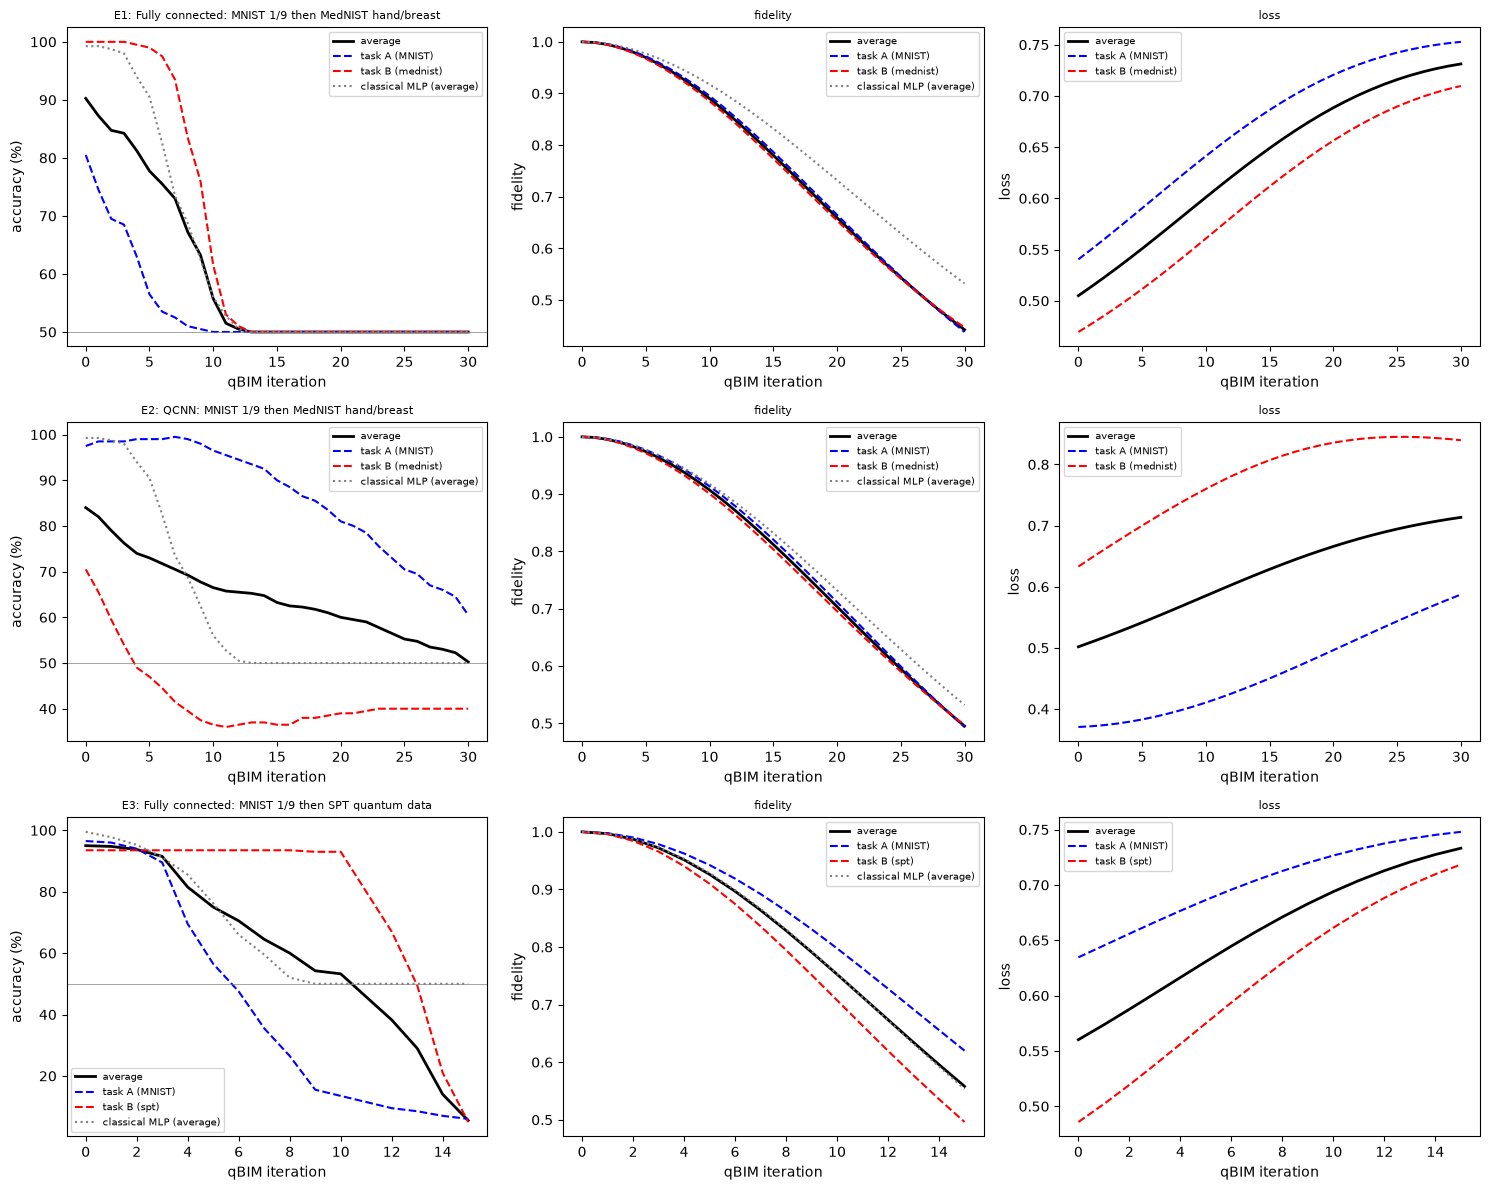

In [24]:
seed0 = RUN_SEEDS[0]
fig, axes = plt.subplots(len(EXPERIMENTS), 3, figsize=(15, 4.0 * len(EXPERIMENTS)))
for r, (exp, cfg) in enumerate(EXPERIMENTS.items()):
    c = ATT[(exp, seed0)]["curve"]; cm = ATT[(exp, seed0)]["curve_mlp"]; it = np.arange(len(c))
    for j, (key, lab) in enumerate((("acc", "accuracy (%)"), ("fid", "fidelity"), ("loss", "loss"))):
        ax = axes[r, j]
        ax.plot(it, c[key + "_avg"], "k-", lw=2, label="average"); ax.plot(it, c[key + "_A"], "b--", label="task A (MNIST)"); ax.plot(it, c[key + "_B"], "r--", label=f"task B ({cfg['task_b']})")
        if key != "loss": ax.plot(it, cm[key + "_avg"], color="gray", ls=":", label="classical MLP (average)")
        if key == "acc": ax.axhline(50, color="gray", lw=0.5)
        ax.set_xlabel("qBIM iteration"); ax.set_ylabel(lab); ax.set_title(f"{exp}: {cfg['title']}" if j == 0 else lab, fontsize=8); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

### Adversarial examples (paper Fig. 3)

Clean and universally perturbed inputs (same perturbation for both tasks and for every sample), picked as the first test sample of each class that is correctly classified before and misclassified after the attack. Because the perturbed state is re-normalised the grey levels differ.

**Reading note for this run.** In E1 the perturbed classifier answers *class 0 for every input* (see section 7), so the class-0 samples (digit 1, Hand) are never misclassified; for them the notebook falls back to the first sample of the class and the title shows `pred. 0 (true 0)`. The perturbed images are visibly destroyed (fidelity 0.4 to 0.5), unlike the paper's Fig. 3.


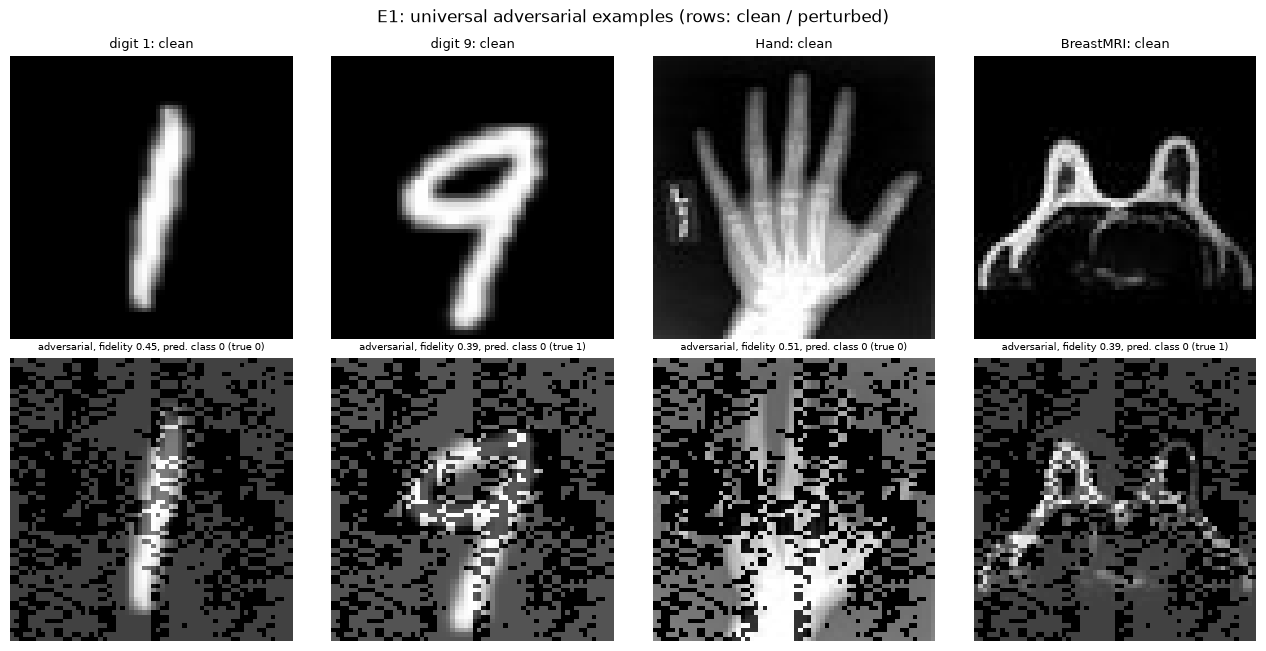

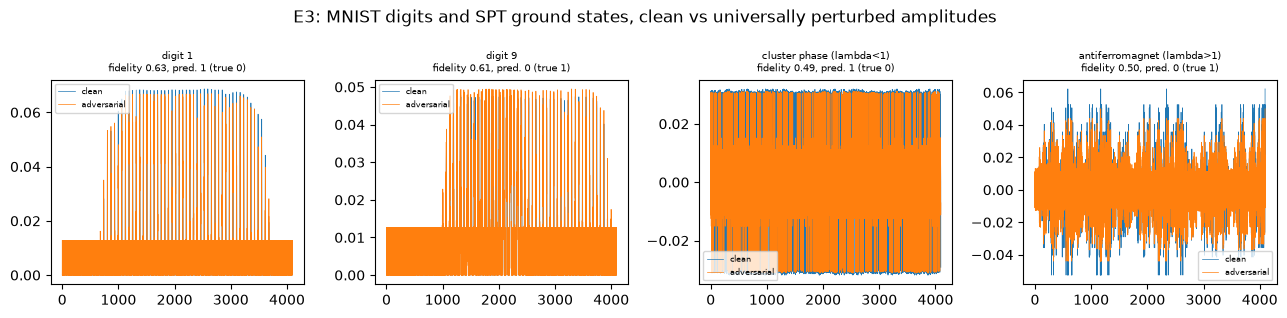

In [25]:
for exp in ("E1", "E3"):
    a = ATT[(exp, seed0)]; cfg = EXPERIMENTS[exp]; model = ARCH[cfg["arch"]]; th = STORE[(exp, seed0)]["thAB"]
    with torch.no_grad(): p0 = forward(model, a["X0"], th).argmax(1); p1 = forward(model, a["Xadv"], th).argmax(1)
    fid = ((a["Xadv"] / a["Xadv"].norm(dim=1, keepdim=True) * a["X0"]).sum(1)) ** 2
    fig, axes = plt.subplots(2, 4, figsize=(13, 6.6)) if exp == "E1" else plt.subplots(1, 4, figsize=(13, 3.2))
    axes = np.atleast_2d(axes)
    for k, (t, c) in enumerate([(0, 0), (0, 1), (1, 0), (1, 1)]):
        cand = torch.where((a["tid"] == t) & (a["y"] == c) & (p0 == a["y"]) & (p1 != a["y"]))[0]
        i = int(cand[0]) if len(cand) else int(torch.where((a["tid"] == t) & (a["y"] == c))[0][0])
        nm = CLASS_NAMES["mnist" if t == 0 else cfg["task_b"]][c]
        if exp == "E1":
            axes[0, k].imshow(a["X0"][i].reshape(64, 64), cmap="gray"); axes[0, k].set_title(f"{nm}: clean", fontsize=9)
            axes[1, k].imshow(a["Xadv"][i].reshape(64, 64), cmap="gray"); axes[1, k].set_title(f"adversarial, fidelity {float(fid[i]):.2f}, pred. class {int(p1[i])} (true {c})", fontsize=7)
            axes[0, k].axis("off"); axes[1, k].axis("off")
        else:
            ax = axes[0, k]; ax.plot(a["X0"][i].numpy(), lw=0.5, label="clean"); ax.plot(a["Xadv"][i].numpy(), lw=0.5, label="adversarial")
            ax.set_title(f"{nm}\nfidelity {float(fid[i]):.2f}, pred. {int(p1[i])} (true {c})", fontsize=7); ax.legend(fontsize=6)
    plt.suptitle(f"{exp}: universal adversarial examples (rows: clean / perturbed)" if exp == "E1" else f"{exp}: MNIST digits and SPT ground states, clean vs universally perturbed amplitudes"); plt.tight_layout(); plt.show()

## 6. Is the perturbation really "universal"? Controls the paper does not have

The paper concludes that the average gradient of two tasks yields one perturbation that works for both. Three things have to be separated: (i) how strong is the effect of a **random** sign perturbation of exactly the same size (same step, same clipping, same re-normalisation)?
(ii) does the **per-task** gradient (of task A only, or of task B only) work as well on its own task and on the other one? (iii) what does an attack that is **not** universal (each sample uses its own gradient) achieve at the same budget?
The bar chart shows the average accuracy of the two tasks after each attack; the table above has all numbers. Error bars are 95 % Wilson intervals of the average accuracy (400 samples).

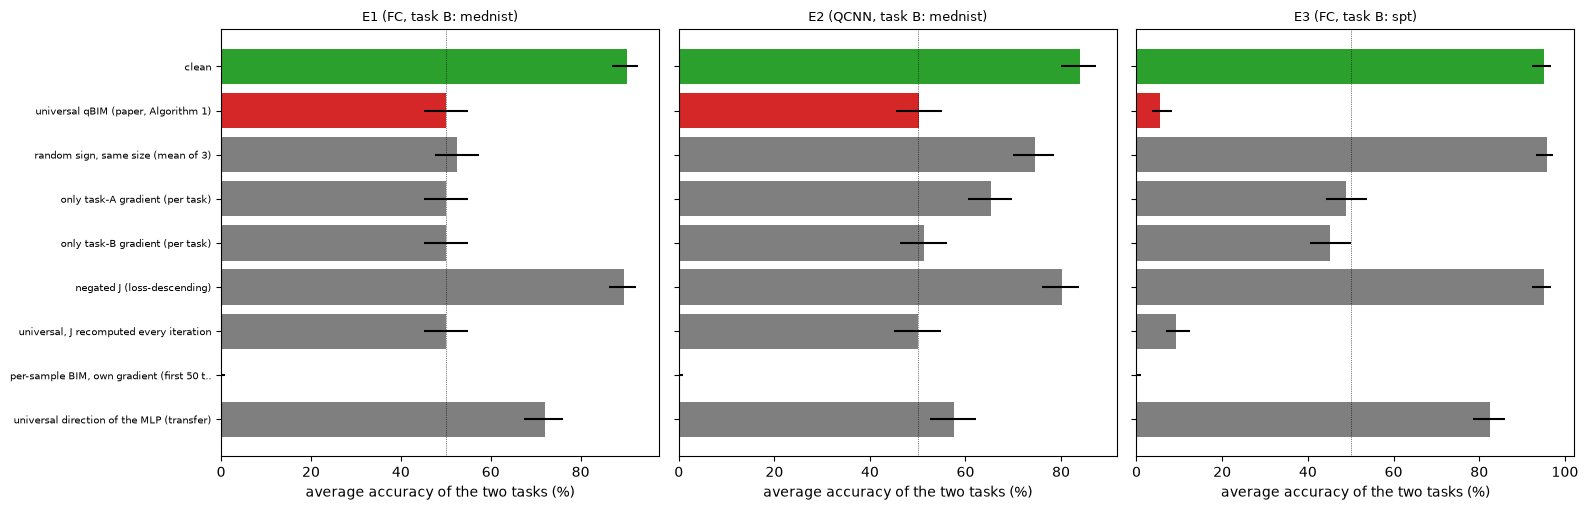

In [26]:
fig, axes = plt.subplots(1, len(EXPERIMENTS), figsize=(16, 5.2), sharey=True)
for ax, (exp, cfg) in zip(axes, EXPERIMENTS.items()):
    t = ATT[(exp, seed0)]["table"]; q = t[(t.model == "quantum") & ~t.attack.str.startswith("   ")].reset_index(drop=True)
    n_tot = 2 * N_TEST; lab = [a if len(a) < 42 else a[:40] + ".." for a in q.attack]
    err = [[v - wilson(round(v * n_tot / 100), n_tot)[0] for v in q.acc_avg], [wilson(round(v * n_tot / 100), n_tot)[1] - v for v in q.acc_avg]]
    cols = ["tab:green" if a == "clean" else "tab:red" if "Algorithm 1" in a else "tab:gray" for a in q.attack]
    ax.barh(range(len(q)), q.acc_avg, xerr=np.clip(err, 0, None), color=cols); ax.set_yticks(range(len(q))); ax.set_yticklabels(lab, fontsize=7); ax.invert_yaxis()
    ax.axvline(50, color="k", lw=0.5, ls=":"); ax.set_xlabel("average accuracy of the two tasks (%)"); ax.set_title(f"{exp} ({cfg['arch']}, task B: {cfg['task_b']})", fontsize=9)
plt.tight_layout(); plt.show()

### Attack strength sweep and a comparison at equal fidelity

With the paper's strength the added vector `eps * sgn(J)` has an L2 norm of `eps * sqrt(4096) = 1.28` (0.96 for eps = 0.015), larger than the norm 1 of the state itself, so "small" depends on the measure. The sweep runs the universal attack and a random sign vector for fractions and multiples of the paper's eps.
Left: average accuracy against eps. Right: average accuracy against the average fidelity between clean and perturbed state; the dotted vertical line is the fidelity the paper reports, so the two attacks can be compared **at the same fidelity**.

E1: universal attack, interpolated average accuracy at the paper's fidelity 0.79: 50.3 % | random sign at the same fidelity: 74.9 %
E2: universal attack, interpolated average accuracy at the paper's fidelity 0.815: 63.1 % | random sign at the same fidelity: 85.2 %
E3: universal attack, interpolated average accuracy at the paper's fidelity 0.63: 24.3 % | random sign at the same fidelity: 94.9 %


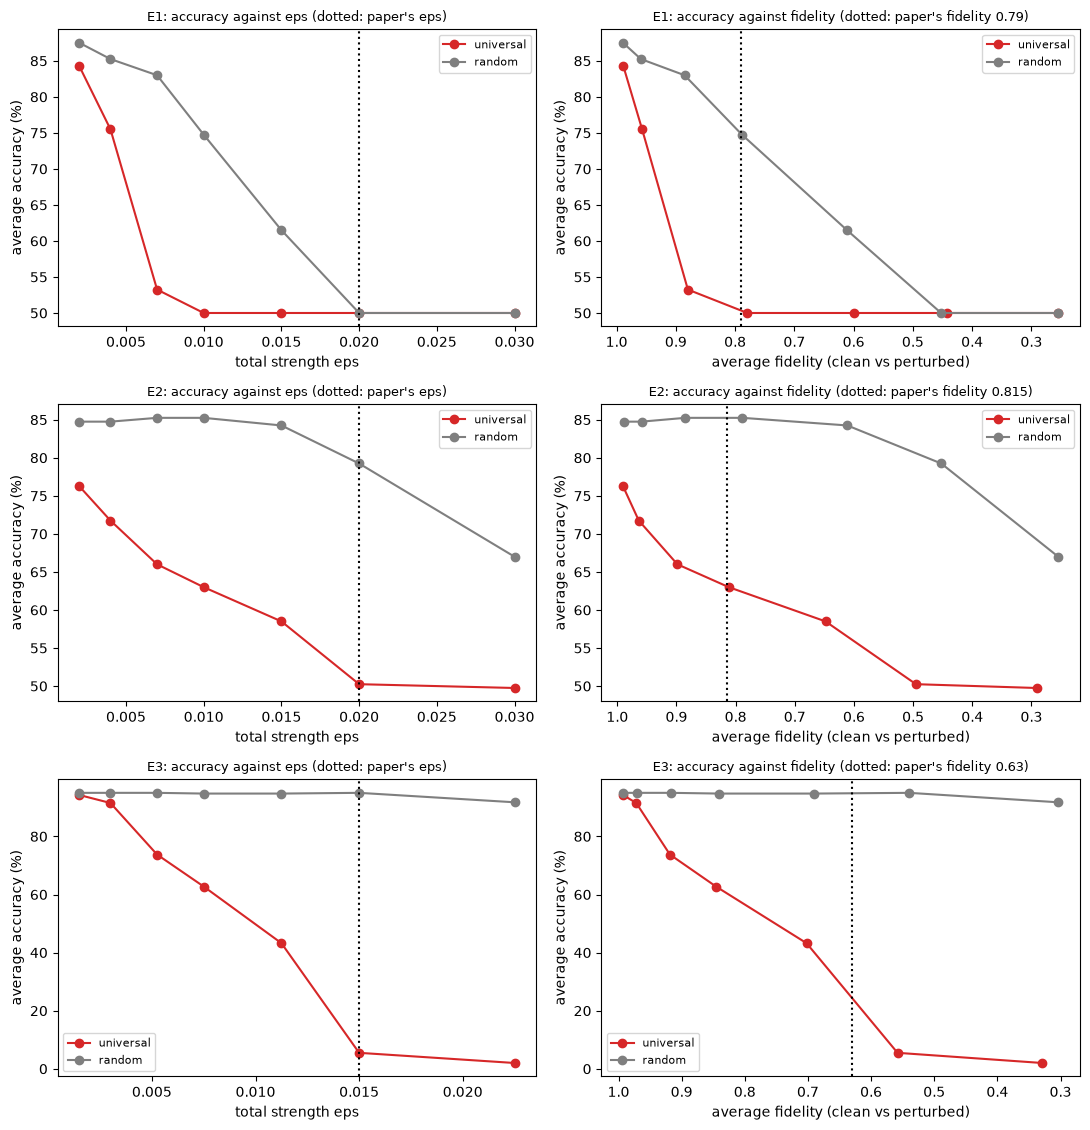

In [27]:
PFID = {"E1": 0.79, "E2": 0.815, "E3": 0.63}
fig, axes = plt.subplots(len(EXPERIMENTS), 2, figsize=(11, 3.8 * len(EXPERIMENTS)))
for r, (exp, cfg) in enumerate(EXPERIMENTS.items()):
    sw = ATT[(exp, seed0)]["sweep"]
    for nm, col in (("universal", "tab:red"), ("random", "tab:gray")):
        s = sw[sw.attack == nm]
        axes[r, 0].plot(s.eps, s.acc, "o-", color=col, label=nm); axes[r, 1].plot(s.fid, s.acc, "o-", color=col, label=nm)
    axes[r, 0].axvline(cfg["eps"], color="k", ls=":"); axes[r, 0].set_xlabel("total strength eps"); axes[r, 0].set_ylabel("average accuracy (%)"); axes[r, 0].set_title(f"{exp}: accuracy against eps (dotted: paper's eps)", fontsize=9); axes[r, 0].legend(fontsize=8)
    axes[r, 1].axvline(PFID[exp], color="k", ls=":"); axes[r, 1].invert_xaxis(); axes[r, 1].set_xlabel("average fidelity (clean vs perturbed)"); axes[r, 1].set_ylabel("average accuracy (%)")
    axes[r, 1].set_title(f"{exp}: accuracy against fidelity (dotted: paper's fidelity {PFID[exp]})", fontsize=9); axes[r, 1].legend(fontsize=8)
    u = sw[sw.attack == "universal"].sort_values("fid")
    print(f"{exp}: universal attack, interpolated average accuracy at the paper's fidelity {PFID[exp]}: {np.interp(PFID[exp], u.fid.values, u.acc.values):.1f} %"
          f" | random sign at the same fidelity: {np.interp(PFID[exp], sw[sw.attack=='random'].sort_values('fid').fid.values, sw[sw.attack=='random'].sort_values('fid').acc.values):.1f} %")
plt.tight_layout(); plt.show()

## 7. Side by side with the paper: a verdict for every number

Tolerance: 2 percentage points for accuracies, 0.02 for fidelities, 0.05 for losses (the losses are printed with one or two digits in the paper). `reproduced` = within tolerance. For accuracies of the clean merged classifier `exceeded` / `not reached` mean higher / lower than the paper;
for accuracies under attack `exceeded` means a stronger attack (lower accuracy) than the paper reports and `not reached` a weaker one; fidelities and losses are marked `differs (higher / lower)`. When several seeds are run the notebook value is the mean.
The test sets have 200 samples per task, so a single accuracy has a 95 % interval of about +/- 6 points (printed in the last column for single-seed runs).

In [28]:
PAPER = {
    "E1": dict(alone=97.6, mA=94.5, mB=92.0, mavg=93.3, aA=24.5, aB=32.5, aavg=28.5, fA=0.84, fB=0.76, favg=0.79, l0=0.62, lA=0.73, lB=0.70, lavg=0.8),
    "E2": dict(alone=">95", mA=92.1, mB=89.7, mavg=91.0, aA=31.5, aB=36.5, aavg=34.0, fA=0.85, fB=0.78, favg=0.815),
    "E3": dict(alone=">95", mA=98.6, mB=97.5, mavg=98.0, aA=4.0, aB=36.5, aavg=20.3, favg=0.63),
}
TOL = {"acc": 2.0, "fid": 0.02, "loss": 0.05}

def verdict(kind, paper, ours):
    if isinstance(paper, str):                                  # ">95": one-sided claim
        return "reproduced" if ours >= float(paper[1:]) - 2.0 else "not reached"
    tol = TOL["acc"] if kind in ("clean", "attack") else TOL["fid"] if kind == "fid" else TOL["loss"]
    d = ours - paper
    if abs(d) <= tol: return "reproduced"
    if kind == "clean": return "exceeded" if d > 0 else "not reached"
    if kind == "attack": return "exceeded (stronger attack)" if d < 0 else "not reached (weaker attack)"
    return "differs (higher)" if d > 0 else "differs (lower)"

def agg(vals): return float(np.mean(vals)), (float(np.std(vals)) if len(vals) > 1 else 0.0)
def fmt(m, s, kind): return (f"{m:.3f}" if kind in ("fid", "loss") else f"{m:.1f}") + (f" +- {s:.3f}" if s and kind in ("fid", "loss") else f" +- {s:.1f}" if s else "")

rowsC = []
for exp, cfg in EXPERIMENTS.items():
    P = PAPER[exp]; seeds = [s for (e, s) in ATT if e == exp]
    get = lambda f: agg([f(ATT[(exp, s)], STORE[(exp, s)]) for s in seeds])
    items = [
        ("task-A accuracy after task A alone", "clean", P["alone"], get(lambda a, st: st["accA_alone"])),
        ("merged classifier, task A accuracy", "clean", P["mA"], get(lambda a, st: a["curve"].acc_A.iloc[0])),
        ("merged classifier, task B accuracy", "clean", P["mB"], get(lambda a, st: a["curve"].acc_B.iloc[0])),
        ("merged classifier, average accuracy", "clean", P["mavg"], get(lambda a, st: a["curve"].acc_avg.iloc[0])),
        ("after universal attack, task A accuracy", "attack", P["aA"], get(lambda a, st: a["curve"].acc_A.iloc[-1])),
        ("after universal attack, task B accuracy", "attack", P["aB"], get(lambda a, st: a["curve"].acc_B.iloc[-1])),
        ("after universal attack, average accuracy", "attack", P["aavg"], get(lambda a, st: a["curve"].acc_avg.iloc[-1])),
    ]
    if "fA" in P: items += [("fidelity, task A", "fid", P["fA"], get(lambda a, st: a["curve"].fid_A.iloc[-1])), ("fidelity, task B", "fid", P["fB"], get(lambda a, st: a["curve"].fid_B.iloc[-1]))]
    items += [("fidelity, average", "fid", P["favg"], get(lambda a, st: a["curve"].fid_avg.iloc[-1]))]
    if "l0" in P:
        items += [("loss before attack, average", "loss", P["l0"], get(lambda a, st: a["curve"].loss_avg.iloc[0])),
                  ("loss after attack, task A", "loss", P["lA"], get(lambda a, st: a["curve"].loss_A.iloc[-1])),
                  ("loss after attack, task B", "loss", P["lB"], get(lambda a, st: a["curve"].loss_B.iloc[-1])),
                  ("loss after attack, average", "loss", P["lavg"], get(lambda a, st: a["curve"].loss_avg.iloc[-1]))]
    for nm, kind, pv, (m, s) in items:
        note = ""
        if len(seeds) == 1 and kind in ("clean", "attack") and not nm.startswith("task-A accuracy after") and "average" not in nm:
            lo_, hi_ = wilson(round(m * N_TEST / 100), N_TEST); note = f"95% CI [{lo_:.0f}, {hi_:.0f}]"
        if exp == "E3" and nm.endswith("task A accuracy") and "universal" in nm: note = "paper lists 4 % and 36.5 % without saying which task is which; order taken as printed"
        rowsC.append(dict(experiment=exp, claim=nm, paper=pv if isinstance(pv, str) else (f"{pv:.3f}" if kind in ("fid", "loss") else f"{pv:.1f}"), notebook=fmt(m, s, kind), verdict=verdict(kind, pv, m), note=note))
    # qualitative claims
    cA, cB, cavg = get(lambda a, st: a["curve"].acc_A.iloc[-1])[0], get(lambda a, st: a["curve"].acc_B.iloc[-1])[0], get(lambda a, st: a["curve"].acc_avg.iloc[-1])[0]
    rowsC.append(dict(experiment=exp, claim="one perturbation fools both tasks (both below 50 %, chance)", paper="yes", notebook=f"A {cA:.1f}, B {cB:.1f}", verdict="reproduced" if max(cA, cB) < 50 else "not reached", note=""))
    rowsC.append(dict(experiment=exp, claim="earlier-trained task A is the more vulnerable (lower accuracy than B)", paper="yes", notebook=f"A {cA:.1f} vs B {cB:.1f}", verdict="reproduced" if cA < cB else "not reached", note="differences below ~6 points are within the sampling noise of 200 test samples"))
cE = {e: agg([ATT[(e, s)]["curve"].acc_avg.iloc[-1] for (ee, s) in ATT if ee == e])[0] for e in EXPERIMENTS}
rowsC.append(dict(experiment="E1 vs E2", claim="QCNN and fully connected circuits are about equally vulnerable (average accuracy within 10 points)", paper="28.5 vs 34", notebook=f"{cE['E1']:.1f} vs {cE['E2']:.1f}", verdict="reproduced" if abs(cE["E1"] - cE["E2"]) <= 10 else "not reached", note=""))
rowsC.append(dict(experiment="E1", claim="the four examples of Fig. 3 have fidelity 0.51-0.52", paper="0.51-0.52", notebook="see Fig. 3 titles", verdict="cannot be checked", note="four hand-picked samples; their identity is not given"))
COMP = pd.DataFrame(rowsC)
print(COMP.to_string(index=False))
print("\nverdict counts:\n", COMP.verdict.value_counts().to_string())

experiment                                                                                              claim      paper          notebook                     verdict                                                                                  note
        E1                                                                 task-A accuracy after task A alone       97.6              99.0                  reproduced                                                                                      
        E1                                                                 merged classifier, task A accuracy       94.5              80.5                 not reached                                                                       95% CI [74, 85]
        E1                                                                 merged classifier, task B accuracy       92.0             100.0                    exceeded                                                                      95% C

In [29]:
# Universality in one table: the attack that the paper proposes against the controls, per experiment (average accuracy of the two tasks after the attack, %).
rowsU = []
for (exp, seed), a in ATT.items():
    t = a["table"].set_index("attack"); q = t[t.model == "quantum"]
    def v(prefix):
        m = [k for k in q.index if k.startswith(prefix)]; return float(q.loc[m[0], "acc_avg"]) if m else float("nan")
    rowsU.append(dict(experiment=exp, seed=seed, clean=v("clean"), universal_paper=v("universal qBIM"), random_same_size=v("random sign"),
                      task_A_gradient_only=v("only task-A"), task_B_gradient_only=v("only task-B"), J_recomputed=v("universal, J recomputed"),
                      MLP_clean=float(a["table"][(a["table"].model == "MLP") & (a["table"].attack == "clean")].acc_avg.iloc[0]),
                      MLP_own_universal=float(a["table"][(a["table"].model == "MLP") & a["table"].attack.str.contains("own gradient")].acc_avg.iloc[0]),
                      MLP_with_quantum_J=float(a["table"][(a["table"].model == "MLP") & a["table"].attack.str.contains("QUANTUM")].acc_avg.iloc[0])))
print(pd.DataFrame(rowsU).round(1).to_string(index=False))
print(f"\ntotal wall-clock of this notebook run: {(time.time()-T_NB0)/60:.1f} min  (FAST_MODE = {FAST_MODE})")

experiment  seed  clean  universal_paper  random_same_size  task_A_gradient_only  task_B_gradient_only  J_recomputed  MLP_clean  MLP_own_universal  MLP_with_quantum_J
        E1    42   90.2             50.0              52.4                  50.0                  50.0          50.0       99.2               50.0                50.0
        E3    42   95.0              5.5              95.8                  49.0                  45.2           9.3       99.5               50.0                98.2
        E2    42   84.0             50.2              74.6                  65.2                  51.2          50.0       99.2               50.0                95.0

total wall-clock of this notebook run: 143.9 min  (FAST_MODE = False)


## 8. Reading the paper critically

**What this run shows** (full budgets, one run, seed 42, 200 test samples per task, so every accuracy has a 95 % interval of about +/- 6 points).

1. **The merged classifiers do not match the paper.** Task-A accuracy after task A alone is 99 % (paper 97.6 %), but after EWC training the merged circuits give A / B = 80.5 / 100 (E1; paper 94.5 / 92.0), 97.5 / 70.5 (E2, QCNN; paper 92.1 / 89.7) and 96.5 / 93.5 (E3, quantum data; paper 98.6 / 97.5).
   The paper does not say how the Fisher matrix was normalised or how the initial angles were drawn, and EWC is sensitive to both (our diagonal empirical Fisher is small, mean about 5e-4 for the fully connected circuit, so lambda = 750 protects task A only weakly: it drops from 99 % to 80.5 % in E1).
2. **The attack is strong, but not in the way the figures of the paper show.** In E3 (quantum data) one perturbation drives both tasks far below chance (6 % and 5 %; paper 4 % and 36.5 %). In E1 and E2 the average accuracy ends at 50.0 % and 50.2 %, not at 28.5 % and 34 %: the column `pred1_avg` of the tables shows that
   in E1 the perturbed classifier answers class 0 for *every* input (50 % is a constant answer, not a classifier that is wrong on purpose). The paper's accuracies below chance (24.5 % on a balanced binary task) would need the perturbation to flip individual samples, not to collapse the state.
3. **Is the perturbation universal across tasks? Partly, and only the quantum-data experiment separates the explanations.** In E3 the gradient of task A alone sends task A to 4.5 % and leaves task B at 93.5 %; the gradient of task B alone sends B to 0 % and leaves A at 90.5 %; the sign of the *mean* gradient of both tasks sends both to about 5 %, while a random sign vector of the same size does nothing (95.8 %).
   So the mean gradient does carry both tasks, which is the paper's central claim, even though the signs of the two per-task gradients agree on only 52 % / 47 % / 50 % of the 4096 coordinates (E1 / E2 / E3), i.e. they are unrelated. In E1 and E2 the controls cannot tell: every gradient-based perturbation collapses the state and so does random noise in E1 (52.4 %).
   Compared at the same fidelity as the paper reports (sweep above), the universal attack gives 50.3 % against 74.9 % for random noise (E1), 63.1 % against 85.2 % (E2) and 24.3 % against 94.9 % (E3), so the gradient direction matters there too, but less dramatically than the paper's figures suggest. Recomputing the gradient at every iteration (the other reading of the text) is about as strong as Algorithm 1 in E1 and E2 (50 % in both) and slightly weaker in E3 (9.3 % against 5.5 %).
4. **"Small perturbation" and fidelity.** With the stated strength 0.02 added to each of the 4096 normalised amplitudes the added vector has L2 norm 1.28, larger than the state itself (0.96 for eps = 0.015); the mean distance between clean and perturbed state is 0.82 (E1), 0.77 (E2), 0.71 (E3) and the measured fidelity is 0.44, 0.50 and 0.56 where the paper reports 0.79, 0.815 and 0.63 for the same strength.
   The paper's fidelities cannot be obtained with the parameters and clipping it states, so its perturbation was evidently smaller or differently normalised. The adversarial images of Fig. 3 here are visibly destroyed. The classical MLP is destroyed just as thoroughly by random noise of this size in E1 and E2 (50 %), so at this strength the result says little about quantum-specific fragility;
   the quantum direction `J` transfers to the MLP only in E1 (where everything collapses), not in E2 or E3 (95 % and 98 % accuracy kept), and the MLP's own universal gradient collapses it everywhere.
5. **"The earlier-trained task is the more vulnerable"** is not supported here: the two tasks end within noise of each other in E1 and E3, and task B is the more vulnerable one in E2 (40 % against 60.5 %).
6. **Per-sample attack.** Its row has a known flaw of this run: the 50 samples taken per task are the *first* 50 test samples, and the test arrays are ordered by class, so they are all class-0 samples. It therefore measures how easily class-0 samples are flipped (they all are: 0 % accuracy), and the comparison row "(same 50+50 samples, universal qBIM)" is equally class-0 only and **not meaningful**
   (for E1 it shows 100 % simply because the collapsed classifier answers class 0). The error bars of that row in the bar chart also assume 400 samples. Exercise 1 repairs this; the main results above and all other controls use the complete test sets.
7. **Inconsistencies in the paper that had to be resolved by a choice:** 1024 versus 4096 input pixels; Rz-Rx-Rz versus Rx-Rz-Rx; hand "MRI" images that are X-rays in MedNIST; the loss values for E1 (task losses 0.73 and 0.70 but an average of 0.8); the order of the 4 % and 36.5 % of E3 and the text that says the SPT task falls sharply; the missing variance over seeds, classical baseline and defence evaluation.
   One data caveat of this notebook: the sign convention of the ground state (largest amplitude positive) is not continuous in lambda, which shows as a single sign-flipped state in the PCA of the quantum data.

**Bottom line.** The mechanism of the paper (the sign of the mean gradient of two tasks fools both tasks) is reproduced clearly for the quantum-data experiment and partially for the image experiments, but the numbers of the paper (accuracies below chance, fidelities 0.79 / 0.63) are not reproduced, because with the stated attack strength the perturbation is larger than the state and collapses the classifier to a constant answer.


## 9. Exercises

1. **Repair the per-sample control.** Replace `torch.arange(N_PERSAMPLE)` in the attack cell by a class-balanced subset (the first `N_PERSAMPLE // 2` samples of each class of each task) and compare per-sample BIM with the universal attack on exactly the same samples.
2. **Catastrophic forgetting.** Train task B with lambda in {0, 100, 750, 5000} (E1) and plot the final accuracy of task A and of task B against lambda. How does the Fisher scale (mean 5e-4) decide the useful range of lambda?
3. **Attack budget.** Add a total L2 budget `||delta||_2 <= 0.3` instead of the per-amplitude `eps` and find the budget at which the universal perturbation beats the random one by the largest margin. Re-draw the paper's Fig. 2 at that budget.
4. **A third task.** Compute `J` from tasks A and B only and test it on a third task (MedNIST `CXR` against `ChestCT`, trained with the same EWC recipe). Is the perturbation universal for a task whose gradient it never saw?
5. **Defence.** Add the universal adversarial examples of a first run to the training set of the classifier (adversarial training) or add depolarising noise to the simulator, retrain, and measure the accuracy under the attack. Does the classical MLP profit more than the quantum circuit?
